## Setup
Environment, imports, configuration printout. Nothing here changes any data.

In [1]:
import sys, subprocess
import os

In [2]:
import sys, os
print(sys.executable)      # the python being used right now
print(sys.prefix)          # the environment folder
print(sys.version)
print(os.environ.get("VIRTUAL_ENV"), os.environ.get("CONDA_DEFAULT_ENV"))

/home/aa8624/thesis_2500/venv/bin/python
/home/aa8624/thesis_2500/venv
3.12.3 (main, Mar 23 2026, 19:04:32) [GCC 13.3.0]
None None


In [3]:
# List the key package versions in this environment 
print("python:", sys.executable)
print(subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
      .split("\n")[0:0] or "")
out = subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
print("\n".join(l for l in out.splitlines() if l.lower().split()[0:1] and l.lower().split()[0] in
      ("torch", "torchvision", "torchaudio", "transformers", "huggingface-hub", "open_clip_torch", "open-clip-torch")))

python: /home/aa8624/thesis_2500/venv/bin/python

open_clip_torch           3.3.0
torch                     2.11.0+cu128
torchvision               0.26.0+cu128
transformers              5.13.0


In [4]:
#Pick the GPU (index from nvidia-smi)
# a quiet GPU index from nvidia-smi
os.environ["CUDA_VISIBLE_DEVICES"] = "3"   

In [5]:
# Imports and config printout. 
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))         
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import size_config as sc
import config
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.preprocessing import StandardScaler

%matplotlib inline
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)


print("PROJECT_ROOT :", config.PROJECT_ROOT)
print("QUICK_RUN    :", config.QUICK_RUN, "  (True = tiny settings, NOT for final results)")
print("family set   :", config.ACTIVE_FAMILY_SET, "| models:", config.MODELS_TO_RUN)
print("seeds        :", config.EXPERIMENT_SEEDS)
try:
    import torch; print("torch        :", torch.__version__, "| CUDA:", torch.cuda.is_available())
except ImportError:
    print("torch not installed (only the logistic-regression models will work)")

PROJECT_ROOT : /data/aa8624/thesis_2500
QUICK_RUN    : False   (True = tiny settings, NOT for final results)
family set   : diffusion_split | models: ['spectral_lr', 'handcrafted_lr', 'lbp_lr', 'cnn_densenet', 'supcon', 'npr', 'clip_frozen', 'biomedclip_frozen', 'rad_dino', 'dinov2_frozen']
seeds        : [42, 43, 44]
torch        : 2.11.0+cu128 | CUDA: True


In [6]:
# Number of data-loader workers for the CNN detectors
config.CNN_NUM_WORKERS = 4

**Optional installs (commented out on purpose).** These two lines change the Python environment, so they are not run
automatically. Uncomment and run them once if `import open_clip` or the Hugging Face hub version fails in Stage 5, then restart the kernel.

In [9]:
# One-off environment fixes. Execute only once.
!{sys.executable} -m pip uninstall -y huggingface-hub
!{sys.executable} -m pip install "huggingface-hub>=1.5,<2.0"
%pip install open_clip_torch

Found existing installation: huggingface_hub 1.33.0
Uninstalling huggingface_hub-1.33.0:
  Successfully uninstalled huggingface_hub-1.33.0
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
Using cached huggingface_hub-1.33.0-py3-none-any.whl (846 kB)


Note: you may need to restart the kernel to use updated packages.


## Stage 4 — Cross-generator experimental design

#### Cross generator experiment

In [29]:
import importlib, sys, tempfile
from pathlib import Path

# Reload config and every module the experiments use (config first, registry last)
MODULES = ["config", "utils.common", "evaluation.metrics",
           "stage3_forensics.feature_extractors", "stage3_forensics.statistical_analysis",
           "stage3_forensics.extract_features",
           "stage4_experiments.splits", "stage4_experiments.runner",
           "stage5_models.base", "stage5_models.feature_lr", "stage5_models.lbp_lr",
           "stage5_models.torch_common", "stage5_models.cnn_densenet", "stage5_models.supcon",
           "stage5_models.npr_cnn", "stage5_models.foundation_lr", "stage5_models"]
for name in MODULES:
    mod = sys.modules.get(name) or importlib.import_module(name)
    importlib.reload(mod)
import config
from stage4_experiments import runner, splits
from stage5_models import get_detector_class

# The parameters that decide the run
print("config file          :", config.__file__)
print("run folder           :", config.PROJECT_ROOT)
print("pool size            :", config.POOL_SIZE_PER_POOL)
print("QUICK_RUN            :", config.QUICK_RUN, "   (must be False for the real run)")
print("family set           :", config.ACTIVE_FAMILY_SET, list(config.FAMILY_SETS[config.ACTIVE_FAMILY_SET]))
print("balance IP to real   :", config.BALANCE_SYNTH_TO_REAL)
print("seeds                :", config.EXPERIMENT_SEEDS)
print("threshold rule       :", config.THRESHOLD_RULE, "| bootstrap draws:", config.BOOTSTRAP_N)
print("epochs CNN/SupCon/NPR:", config.CNN_EPOCHS, config.SUPCON_EPOCHS, config.NPR_EPOCHS,
      "| patience CNN/NPR:", config.CNN_EARLY_STOP_PATIENCE, config.NPR_EARLY_STOP_PATIENCE)
print("models               :", config.MODELS_TO_RUN)
print("feature table        :", config.FORENSIC_FEATURE_CSV)
print("results file         :", config.DET_RESULTS_CSV,
      "(exists)" if Path(config.DET_RESULTS_CSV).exists() else "(not yet)")

# Every model in MODELS_TO_RUN must resolve to a detector class in the registry
print("\nmodel registry:")
unknown = []
for m in config.MODELS_TO_RUN:
    try:
        cls = get_detector_class(m)
        print(f"  {m:<20s} -> {cls.__name__:<24s} stochastic={getattr(cls, 'stochastic', '?')}")
    except Exception as exc:                                    # noqa: BLE001
        unknown.append((m, repr(exc)))
assert not unknown, f"models not registered: {unknown}"
assert len(config.EXPERIMENT_SEEDS) == 3, "expected three seeds"

# Data: counts per group and split, file and feature checks
master = runner.load_modelling_table()                     # checks columns, finite features, image files
print("\nimages per group and split:")
print(master.groupby(["frequency_group", "split"]).size().unstack().to_string())
assert (master.frequency_group == config.REAL_GROUP).sum() == config.POOL_SIZE_PER_POOL, \
    "real count != pool size"

# Experiment design: builds all experiments and runs every integrity check
exps = splits.build_experiments(master)
print("\n", splits.experiments_overview(exps).to_string(index=False))
print("\nNOTE:", splits.class_balance_warning(exps) or "classes are balanced in every role")
plan = runner.run_all_experiments(master=master, dry_run=True)
print("planned runs:", len(plan))

# Smoke test with one fast model, written to a temporary folder (real results untouched)
scratch = Path(tempfile.mkdtemp(prefix="cxr_smoke_"))
saved = (config.DET_RESULTS_CSV, config.DET_PREDICTIONS_CSV,
         config.DET_MODEL_DIR, config.SAVE_FITTED_MODELS)
config.DET_RESULTS_CSV, config.DET_PREDICTIONS_CSV = scratch / "results.csv", scratch / "predictions.csv"
config.DET_MODEL_DIR, config.SAVE_FITTED_MODELS = scratch / "models", False
try:
    res = runner.run_all_experiments(models=["spectral_lr"], seeds=[42], master=master)
finally:
    (config.DET_RESULTS_CSV, config.DET_PREDICTIONS_CSV,
     config.DET_MODEL_DIR, config.SAVE_FITTED_MODELS) = saved

out = res[res.role.isin(["test_in", "test_cross"])]
display(out.pivot_table(index="experiment", columns="role", values="auroc").round(3))
assert len(res) == 3 * len(exps), "missing result rows"
assert res["auroc"].notna().all(), "NaN AUROC"
print("\nPRE-FLIGHT PASSED - smoke-test files were in", scratch)

config file          : /data/aa8624/thesis_2500/cxr_forensics/config.py
run folder           : /data/aa8624/thesis_2500
pool size            : 2500
QUICK_RUN            : False    (must be False for the real run)
family set           : diffusion_split ['IP', 'CycleGAN', 'Diffusion', 'Diffusion_EditOnly', 'Diffusion_Reconstruction']
balance IP to real   : True
seeds                : [42, 43, 44]
threshold rule       : youden | bootstrap draws: 1000
epochs CNN/SupCon/NPR: 15 30 30 | patience CNN/NPR: 4 6
models               : ['spectral_lr', 'handcrafted_lr', 'lbp_lr', 'cnn_densenet', 'supcon', 'npr', 'clip_frozen', 'biomedclip_frozen', 'rad_dino', 'dinov2_frozen']
feature table        : /data/aa8624/thesis_2500/data/artifact_characterization/stage1_characterisation/per_image_forensic_characteristics.csv
results file         : /data/aa8624/thesis_2500/data/detection/results/cross_generator_results.csv (not yet)

model registry:
  spectral_lr          -> SpectralLR               stochast

                                  experiment                  train                  val              test_in           test_cross       design
                                IP->CycleGAN 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 500 synth c9cd343c9d86
                               IP->Diffusion 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth d2335cd5d060
                      IP->Diffusion_EditOnly 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth bb936ceef383
                IP->Diffusion_Reconstruction 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth 51c71f55e985
                                CycleGAN->IP 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 500 synth f523710c4195
                         CycleGAN->Diffusion 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth d0682

role,test_cross,test_in
experiment,,
CycleGAN->Diffusion,0.599,0.889
CycleGAN->Diffusion_EditOnly,0.532,0.889
CycleGAN->Diffusion_Reconstruction,0.552,0.889
CycleGAN->IP,0.450,0.889
Diffusion->CycleGAN,0.745,0.848
Diffusion->Diffusion_EditOnly,0.631,0.848
Diffusion->Diffusion_Reconstruction,0.783,0.848
Diffusion->IP,0.646,0.848
Diffusion_EditOnly->CycleGAN,0.741,0.638



PRE-FLIGHT PASSED - smoke-test files were in /tmp/cxr_smoke_0jo22uxx


In [ ]:
# ===== Full grid: 5 families (IP, CycleGAN, Diffusion, Diffusion_EditOnly, Diffusion_Reconstruction) =====
# 20 experiments x 10 detectors; DenseNet / SupCon / NPR with 3 seeds, the other 7 once = 320 runs.
import config
from stage4_experiments import runner

assert not config.QUICK_RUN, "QUICK_RUN is on - unset CXR_QUICK_RUN for the real run"
FAMILY_SET = "diffusion_split"

master = runner.load_modelling_table()

# Plan first: how many runs, and how many are already finished
plan = runner.run_all_experiments(family_set_name=FAMILY_SET, master=master, dry_run=True)
print(f"{len(plan)} runs planned")

# Run everything (resumable: finished runs are skipped; failed runs are retried next time)
res = runner.run_all_experiments(family_set_name=FAMILY_SET, master=master)

# Completeness check: 3 result rows (val, test_in, test_cross) per run
expected = 3 * len(plan)
print(f"\nresult rows: {len(res)} of {expected} expected")
done = res.groupby(["experiment", "model", "seed"]).size()
print("runs finished:", len(done), "of", len(plan))
assert len(res) == expected, "some runs are missing or failed - read the FAILED list above and run the cell again"

# First look: mean AUROC per model, in-family vs cross-family
summary = (res[res.role.isin(["test_in", "test_cross"])]
           .pivot_table(index="model", columns="role", values="auroc", aggfunc="mean").round(3))
display(summary)
print("results file     :", config.DET_RESULTS_CSV)
print("predictions file :", config.DET_PREDICTIONS_CSV)

                                  experiment                  train                  val              test_in           test_cross       design
                                IP->CycleGAN 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 500 synth c9cd343c9d86
                               IP->Diffusion 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth d2335cd5d060
                      IP->Diffusion_EditOnly 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth bb936ceef383
                IP->Diffusion_Reconstruction 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth 51c71f55e985
                                CycleGAN->IP 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 500 synth f523710c4195
                         CycleGAN->Diffusion 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth d0682

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

    [clip_frozen] embedding 1000 new / changed images ...
    [clip_frozen] embedding 1000 new / changed images ...
    [clip_frozen] embedding 500 new / changed images ...
[13/320] IP->CycleGAN                 clip_frozen        seed=42 -> AUROC in=0.910 cross=0.819 (76s) | elapsed 79.7 min
    [biomedclip_frozen] embedding 3000 new / changed images ...
    [biomedclip_frozen] embedding 1000 new / changed images ...
    [biomedclip_frozen] embedding 1000 new / changed images ...
    [biomedclip_frozen] embedding 500 new / changed images ...
[14/320] IP->CycleGAN                 biomedclip_frozen  seed=42 -> AUROC in=0.897 cross=0.588 (33s) | elapsed 80.5 min
    [rad_dino] embedding 3000 new / changed images ...


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

    [rad_dino] embedding 1000 new / changed images ...
    [rad_dino] embedding 1000 new / changed images ...
    [rad_dino] embedding 500 new / changed images ...
[15/320] IP->CycleGAN                 rad_dino           seed=42 -> AUROC in=0.936 cross=0.696 (29s) | elapsed 81.2 min
    [dinov2_frozen] embedding 3000 new / changed images ...


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

    [dinov2_frozen] embedding 1000 new / changed images ...
    [dinov2_frozen] embedding 1000 new / changed images ...
    [dinov2_frozen] embedding 500 new / changed images ...
[16/320] IP->CycleGAN                 dinov2_frozen      seed=42 -> AUROC in=0.913 cross=0.775 (31s) | elapsed 81.9 min
[17/320] IP->Diffusion                spectral_lr        seed=42 -> AUROC in=0.708 cross=0.807 (0s) | elapsed 82.0 min
[18/320] IP->Diffusion                handcrafted_lr     seed=42 -> AUROC in=0.720 cross=0.770 (0s) | elapsed 82.1 min
[19/320] IP->Diffusion                lbp_lr             seed=42 -> AUROC in=0.611 cross=0.788 (0s) | elapsed 82.1 min
[20/320] IP->Diffusion                cnn_densenet       seed=42 -> AUROC in=0.994 cross=0.723 (78s) | elapsed 83.6 min
[21/320] IP->Diffusion                cnn_densenet       seed=43 -> AUROC in=0.995 cross=0.639 (183s) | elapsed 86.9 min
[22/320] IP->Diffusion                cnn_densenet       seed=44 -> AUROC in=0.994 cross=0.648 (111s) |

    [clip_frozen] embedding 1500 new / changed images ...
    [clip_frozen] embedding 500 new / changed images ...
[77/320] CycleGAN->IP                 clip_frozen        seed=42 -> AUROC in=0.997 cross=0.646 (231s) | elapsed 402.6 min
    [biomedclip_frozen] embedding 1500 new / changed images ...
    [biomedclip_frozen] embedding 500 new / changed images ...
[78/320] CycleGAN->IP                 biomedclip_frozen  seed=42 -> AUROC in=0.840 cross=0.534 (131s) | elapsed 404.9 min
    [rad_dino] embedding 1500 new / changed images ...
    [rad_dino] embedding 500 new / changed images ...
[79/320] CycleGAN->IP                 rad_dino           seed=42 -> AUROC in=0.822 cross=0.720 (78s) | elapsed 406.3 min
    [dinov2_frozen] embedding 1500 new / changed images ...
    [dinov2_frozen] embedding 500 new / changed images ...
[80/320] CycleGAN->IP                 dinov2_frozen      seed=42 -> AUROC in=0.998 cross=0.586 (68s) | elapsed 407.6 min
[81/320] CycleGAN->Diffusion          spectr

In [11]:
# ===== Full grid: 5 families (IP, CycleGAN, Diffusion, Diffusion_EditOnly, Diffusion_Reconstruction) =====
# 20 experiments x 10 detectors; DenseNet / SupCon / NPR with 3 seeds, the other 7 once = 320 runs.
import config
from stage4_experiments import runner

assert not config.QUICK_RUN, "QUICK_RUN is on - unset CXR_QUICK_RUN for the real run"
FAMILY_SET = "diffusion_split"

master = runner.load_modelling_table()

# Plan first: how many runs, and how many are already finished
plan = runner.run_all_experiments(family_set_name=FAMILY_SET, master=master, dry_run=True)
print(f"{len(plan)} runs planned")

# Run everything (resumable: finished runs are skipped; failed runs are retried next time)
res = runner.run_all_experiments(family_set_name=FAMILY_SET, master=master)

# Completeness check: 3 result rows (val, test_in, test_cross) per run
expected = 3 * len(plan)
print(f"\nresult rows: {len(res)} of {expected} expected")
done = res.groupby(["experiment", "model", "seed"]).size()
print("runs finished:", len(done), "of", len(plan))
assert len(res) == expected, "some runs are missing or failed - read the FAILED list above and run the cell again"

# First look: mean AUROC per model, in-family vs cross-family
summary = (res[res.role.isin(["test_in", "test_cross"])]
           .pivot_table(index="model", columns="role", values="auroc", aggfunc="mean").round(3))
display(summary)
print("results file     :", config.DET_RESULTS_CSV)
print("predictions file :", config.DET_PREDICTIONS_CSV)

                                  experiment                  train                  val              test_in           test_cross       design
                                IP->CycleGAN 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 500 synth c9cd343c9d86
                               IP->Diffusion 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth d2335cd5d060
                      IP->Diffusion_EditOnly 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth bb936ceef383
                IP->Diffusion_Reconstruction 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth 51c71f55e985
                                CycleGAN->IP 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 500 synth f523710c4195
                         CycleGAN->Diffusion 1500 real + 1500 synth 500 real + 500 synth 500 real + 500 synth 500 real + 496 synth d0682

[81/320] CycleGAN->Diffusion          spectral_lr        seed=42 -> skipped (done)
[82/320] CycleGAN->Diffusion          handcrafted_lr     seed=42 -> skipped (done)
[83/320] CycleGAN->Diffusion          lbp_lr             seed=42 -> skipped (done)
[84/320] CycleGAN->Diffusion          cnn_densenet       seed=42 -> skipped (done)
[85/320] CycleGAN->Diffusion          cnn_densenet       seed=43 -> skipped (done)
[86/320] CycleGAN->Diffusion          cnn_densenet       seed=44 -> skipped (done)
[87/320] CycleGAN->Diffusion          supcon             seed=42 -> skipped (done)
[88/320] CycleGAN->Diffusion          supcon             seed=43 -> AUROC in=1.000 cross=0.806 (2495s) | elapsed 45.2 min
[89/320] CycleGAN->Diffusion          supcon             seed=44 -> AUROC in=1.000 cross=0.836 (3390s) | elapsed 103.9 min
[90/320] CycleGAN->Diffusion          npr                seed=42 -> AUROC in=1.000 cross=0.613 (385s) | elapsed 110.6 min
[91/320] CycleGAN->Diffusion          npr           

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

    [clip_frozen] embedding 500 new / changed images ...
[141/320] Diffusion->IP                clip_frozen        seed=42 -> AUROC in=0.965 cross=0.551 (77s) | elapsed 439.2 min
    [biomedclip_frozen] embedding 1495 new / changed images ...
    [biomedclip_frozen] embedding 500 new / changed images ...
[142/320] Diffusion->IP                biomedclip_frozen  seed=42 -> AUROC in=0.829 cross=0.690 (97s) | elapsed 440.9 min
    [rad_dino] embedding 1495 new / changed images ...


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

    [rad_dino] embedding 500 new / changed images ...
[143/320] Diffusion->IP                rad_dino           seed=42 -> AUROC in=0.795 cross=0.780 (53s) | elapsed 441.9 min
    [dinov2_frozen] embedding 1495 new / changed images ...


... (2 outputs left out)

    [rad_dino] embedding 500 new / changed images ...
[207/320] Diffusion_EditOnly->IP       rad_dino           seed=42 -> AUROC in=0.727 cross=0.813 (90s) | elapsed 1284.6 min
    [dinov2_frozen] embedding 1495 new / changed images ...
    [dinov2_frozen] embedding 500 new / changed images ...
[208/320] Diffusion_EditOnly->IP       dinov2_frozen      seed=42 -> AUROC in=0.694 cross=0.742 (79s) | elapsed 1286.0 min
[209/320] Diffusion_EditOnly->CycleGAN spectral_lr        seed=42 -> AUROC in=0.638 cross=0.741 (0s) | elapsed 1286.1 min
[210/320] Diffusion_EditOnly->CycleGAN handcrafted_lr     seed=42 -> AUROC in=0.619 cross=0.525 (0s) | elapsed 1286.2 min
[211/320] Diffusion_EditOnly->CycleGAN lbp_lr             seed=42 -> AUROC in=0.546 cross=0.526 (0s) | elapsed 1286.3 min
[212/320] Diffusion_EditOnly->CycleGAN cnn_densenet       seed=42 -> AUROC in=0.980 cross=0.758 (753s) | elapsed 1300.5 min
[213/320] Diffusion_EditOnly->CycleGAN cnn_densenet       seed=43 -> AUROC in=0.972 cross=0

[269/320] Diffusion_Reconstruction->IP clip_frozen        seed=42 -> AUROC in=0.899 cross=0.571 (43s) | elapsed 2050.6 min
    [biomedclip_frozen] embedding 1495 new / changed images ...
    [biomedclip_frozen] embedding 500 new / changed images ...
[270/320] Diffusion_Reconstruction->IP biomedclip_frozen  seed=42 -> AUROC in=0.783 cross=0.698 (16s) | elapsed 2050.9 min
    [rad_dino] embedding 1495 new / changed images ...
    [rad_dino] embedding 500 new / changed images ...
[271/320] Diffusion_Reconstruction->IP rad_dino           seed=42 -> AUROC in=0.704 cross=0.642 (29s) | elapsed 2051.5 min
    [dinov2_frozen] embedding 1495 new / changed images ...
    [dinov2_frozen] embedding 500 new / changed images ...
[272/320] Diffusion_Reconstruction->IP dinov2_frozen      seed=42 -> AUROC in=0.919 cross=0.546 (21s) | elapsed 2052.0 min
[273/320] Diffusion_Reconstruction->CycleGAN spectral_lr        seed=42 -> AUROC in=0.777 cross=0.734 (0s) | elapsed 2052.0 min
[274/320] Diffusion_Recon

role,test_cross,test_in
model,,
biomedclip_frozen,0.633,0.806
clip_frozen,0.617,0.888
cnn_densenet,0.712,0.993
dinov2_frozen,0.648,0.903
handcrafted_lr,0.609,0.795
lbp_lr,0.582,0.752
npr,0.650,0.962
rad_dino,0.625,0.797
spectral_lr,0.676,0.772


results file     : /data/aa8624/thesis_2500/data/detection/results/cross_generator_results.csv
predictions file : /data/aa8624/thesis_2500/data/detection/results/cross_generator_predictions.csv


In [12]:
R = pd.read_csv(config.DET_RESULTS_CSV)
R = R.drop_duplicates(["experiment", "model", "seed", "role", "design"], keep="last")
print(config.DET_RESULTS_CSV)
print(R.shape, "| roles:", R.role.unique().tolist(),
      "| experiments:", R.experiment.nunique(), "| models:", R.model.nunique())

# Completeness: 20 experiments x (7 deterministic + 3 stochastic x 3 seeds) = 320 runs, 3 role rows each
runs = R.groupby(["experiment", "model", "seed"]).ngroups
print(f"runs present: {runs} / 320", "" if runs == 320 else "  <-- INCOMPLETE, do not report as final")

FAM = list(config.FAMILY_SETS[config.ACTIVE_FAMILY_SET])          # fixed family order
MODELS = [m for m in config.MODELS_TO_RUN if m in R.model.unique()]

# ---- Unseen generator (test_cross): rows = train -> test, columns = detector, mean over seeds
cross = R[R.role == "test_cross"]
T = (cross.groupby(["train_family", "test_family", "model"]).auroc.mean().unstack("model")[MODELS])
T = T.reindex(pd.MultiIndex.from_product([FAM, FAM]).intersection(T.index)).round(3)
print("\nCROSS-GENERATOR AUROC (unseen family; mean over seeds)")
display(T)

# ---- Seen family (test_in): the ceiling for each training family
inn = R[R.role == "test_in"]
C = inn.groupby(["train_family", "model"]).auroc.mean().unstack("model")[MODELS].reindex(FAM).round(3)
print("\nSAME-FAMILY AUROC (test_in)")
display(C)

# ---- Drop from seen to unseen: how much is lost when the generator changes
drop = T.copy()
for (a, b) in T.index:
    drop.loc[(a, b)] = (C.loc[a] - T.loc[(a, b)]).values
print("\nDROP = same-family AUROC minus cross-generator AUROC (positive = detector fails to transfer)")
display(drop.round(3))

# ---- One-number summaries
S = pd.DataFrame({"mean AUROC": T.mean(axis=1), "worst": T.min(axis=1),
                  "best detector": T.idxmax(axis=1), "best AUROC": T.max(axis=1)}).round(3)
print("\nPER PAIR (hardest first)")
display(S.sort_values("mean AUROC"))

M = pd.DataFrame({"mean cross": T.mean(), "min cross": T.min(), "mean seen": C.mean()}).round(3)
M["drop"] = (M["mean seen"] - M["mean cross"]).round(3)
print("\nPER DETECTOR (all 20 transfer pairs)")
display(M.sort_values("mean cross", ascending=False))

# ---- Seed spread for the stochastic models (std of AUROC across seeds)
sd = (cross[cross.model.isin(["cnn_densenet", "supcon", "npr"])]
      .groupby(["train_family", "test_family", "model"]).auroc.std().unstack("model").round(3))
print("\nSEED SPREAD (std over 3 seeds, stochastic models only)")
display(sd)

/data/aa8624/thesis_2500/data/detection/results/cross_generator_results.csv
(960, 30) | roles: ['val', 'test_in', 'test_cross'] | experiments: 20 | models: 10
runs present: 320 / 320 

CROSS-GENERATOR AUROC (unseen family; mean over seeds)


model                                              spectral_lr  handcrafted_lr  lbp_lr  cnn_densenet  supcon    npr  clip_frozen  biomedclip_frozen  rad_dino  dinov2_frozen
IP                       CycleGAN                        0.544           0.531   0.430         0.610   0.626  0.536        0.819              0.588     0.696          0.775
                         Diffusion                       0.807           0.770   0.788         0.670   0.663  0.641        0.539              0.627     0.682          0.521
                         Diffusion_EditOnly              0.627           0.625   0.532         0.612   0.637  0.580        0.578              0.602     0.656          0.588
                         Diffusion_Reconstruction        0.738           0.743   0.737         0.585   0.593  0.615        0.536              0.574     0.517          0.586
CycleGAN                 IP                              0.450           0.436   0.468         0.540   0.583  0.473        0.646              0.534     0.720          0.586
                         Diffusion                       0.599           0.605   0.577         0.828   0.834  0.575        0.589              0.613     0.618          0.746
                         Diffusion_EditOnly              0.532           0.502   0.500         0.524   0.528  0.522        0.514              0.513     0.532          0.536
                         Diffusion_Reconstruction        0.552           0.417   0.418         0.523   0.563  0.525        0.530              0.525     0.450          0.567
Diffusion                IP                              0.646           0.630   0.580         0.627   0.698  0.598        0.551              0.690     0.780          0.446
                         CycleGAN                        0.745           0.568   0.539         0.834   0.800  0.514        0.510              0.625     0.703          0.799
                         Diffusion_EditOnly              0.631           0.569   0.534         0.638   0.707  0.643        0.554              0.644     0.686          0.531
                         Diffusion_Reconstruction        0.783           0.758   0.756         0.889   0.937  0.941        0.731              0.742     0.566          0.649
Diffusion_EditOnly       IP                              0.669           0.700   0.580         0.813   0.817  0.666        0.764              0.753     0.813          0.742
                         CycleGAN                        0.741           0.525   0.526         0.716   0.706  0.731        0.693              0.566     0.596          0.785
                         Diffusion                       0.851           0.783   0.769         0.953   0.960  0.962        0.751              0.772     0.732          0.727
                         Diffusion_Reconstruction        0.779           0.719   0.710         0.863   0.861  0.874        0.700              0.673     0.539          0.749
Diffusion_Reconstruction IP                              0.630           0.642   0.574         0.667   0.698  0.605        0.571              0.698     0.642          0.546
                         CycleGAN                        0.734           0.290   0.323         0.629   0.640  0.389        0.347              0.518     0.460          0.673
                         Diffusion                       0.836           0.798   0.781         0.992   0.995  0.979        0.846              0.795     0.581          0.833
                         Diffusion_EditOnly              0.621           0.565   0.527         0.720   0.730  0.639        0.569              0.614     0.537          0.581


SAME-FAMILY AUROC (test_in)


model,spectral_lr,handcrafted_lr,lbp_lr,cnn_densenet,supcon,npr,clip_frozen,biomedclip_frozen,rad_dino,dinov2_frozen
train_family,,,,,,,,,,
IP,0.708,0.720,0.611,0.994,0.995,0.964,0.910,0.897,0.936,0.913
CycleGAN,0.889,0.976,0.967,1.000,1.000,1.000,0.997,0.840,0.822,0.998
Diffusion,0.848,0.854,0.845,1.000,1.000,0.993,0.965,0.829,0.795,0.993
Diffusion_EditOnly,0.638,0.619,0.546,0.975,0.982,0.878,0.670,0.680,0.727,0.694
Diffusion_Reconstruction,0.777,0.804,0.791,0.993,0.995,0.974,0.899,0.783,0.704,0.919



DROP = same-family AUROC minus cross-generator AUROC (positive = detector fails to transfer)


model                                              spectral_lr  handcrafted_lr  lbp_lr  cnn_densenet  supcon    npr  clip_frozen  biomedclip_frozen  rad_dino  dinov2_frozen
IP                       CycleGAN                        0.164           0.189   0.181         0.384   0.369  0.428        0.091              0.309     0.240          0.138
                         Diffusion                      -0.099          -0.050  -0.177         0.324   0.332  0.323        0.371              0.270     0.254          0.392
                         Diffusion_EditOnly              0.081           0.095   0.079         0.382   0.358  0.384        0.332              0.295     0.280          0.325
                         Diffusion_Reconstruction       -0.030          -0.023  -0.126         0.409   0.402  0.349        0.374              0.323     0.419          0.327
CycleGAN                 IP                              0.439           0.540   0.499         0.460   0.417  0.527        0.351              0.306     0.102          0.412
                         Diffusion                       0.290           0.371   0.390         0.172   0.166  0.425        0.408              0.227     0.204          0.252
                         Diffusion_EditOnly              0.357           0.474   0.467         0.476   0.472  0.478        0.483              0.327     0.290          0.462
                         Diffusion_Reconstruction        0.337           0.559   0.549         0.477   0.437  0.475        0.467              0.315     0.372          0.431
Diffusion                IP                              0.202           0.224   0.265         0.373   0.302  0.395        0.414              0.139     0.015          0.547
                         CycleGAN                        0.103           0.286   0.306         0.166   0.200  0.479        0.455              0.204     0.092          0.194
                         Diffusion_EditOnly              0.217           0.285   0.311         0.362   0.293  0.350        0.411              0.185     0.109          0.462
                         Diffusion_Reconstruction        0.065           0.096   0.089         0.111   0.063  0.052        0.234              0.087     0.229          0.344
Diffusion_EditOnly       IP                             -0.031          -0.081  -0.034         0.162   0.165  0.212       -0.094             -0.073    -0.086         -0.048
                         CycleGAN                       -0.103           0.094   0.020         0.259   0.276  0.147       -0.023              0.114     0.131         -0.091
                         Diffusion                      -0.213          -0.164  -0.223         0.022   0.022 -0.084       -0.081             -0.092    -0.005         -0.033
                         Diffusion_Reconstruction       -0.141          -0.100  -0.164         0.112   0.121  0.004       -0.030              0.007     0.188         -0.055
Diffusion_Reconstruction IP                              0.147           0.162   0.217         0.326   0.297  0.369        0.328              0.085     0.062          0.373
                         CycleGAN                        0.043           0.514   0.468         0.364   0.355  0.585        0.552              0.265     0.244          0.246
                         Diffusion                      -0.059           0.006   0.010         0.001   0.000 -0.005        0.053             -0.012     0.123          0.086
                         Diffusion_EditOnly              0.156           0.239   0.264         0.273   0.265  0.335        0.330              0.169     0.167          0.338

... (2 outputs left out)


PER DETECTOR (all 20 transfer pairs)


,mean cross,min cross,mean seen,drop
model,,,,
supcon,0.729,0.528,0.994,0.265
cnn_densenet,0.712,0.523,0.992,0.280
spectral_lr,0.676,0.450,0.772,0.096
npr,0.650,0.389,0.962,0.312
dinov2_frozen,0.648,0.446,0.903,0.255
biomedclip_frozen,0.633,0.513,0.806,0.173
rad_dino,0.625,0.450,0.797,0.172
clip_frozen,0.617,0.347,0.888,0.271
handcrafted_lr,0.609,0.290,0.795,0.186



SEED SPREAD (std over 3 seeds, stochastic models only)


model                                              cnn_densenet    npr  supcon
train_family             test_family                                          
CycleGAN                 Diffusion                        0.052  0.034   0.027
                         Diffusion_EditOnly               0.020  0.011   0.005
                         Diffusion_Reconstruction         0.019  0.017   0.020
                         IP                               0.027  0.003   0.017
Diffusion                CycleGAN                         0.014  0.007   0.019
                         Diffusion_EditOnly               0.024  0.002   0.029
                         Diffusion_Reconstruction         0.016  0.015   0.015
                         IP                               0.032  0.005   0.012
Diffusion_EditOnly       CycleGAN                         0.037  0.045   0.019
                         Diffusion                        0.012  0.007   0.012
                         Diffusion_Reconstruction         0.032  0.025   0.020
                         IP                               0.033  0.033   0.015
Diffusion_Reconstruction CycleGAN                         0.029  0.039   0.021
                         Diffusion                        0.002  0.001   0.001
                         Diffusion_EditOnly               0.003  0.003   0.009
                         IP                               0.010  0.016   0.016
IP                       CycleGAN                         0.040  0.036   0.042
                         Diffusion                        0.046  0.065   0.045
                         Diffusion_EditOnly               0.043  0.024   0.044
                         Diffusion_Reconstruction         0.049  0.052   0.036

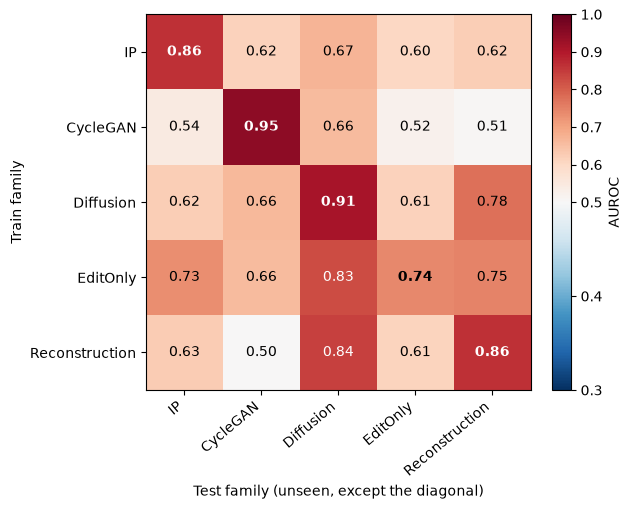

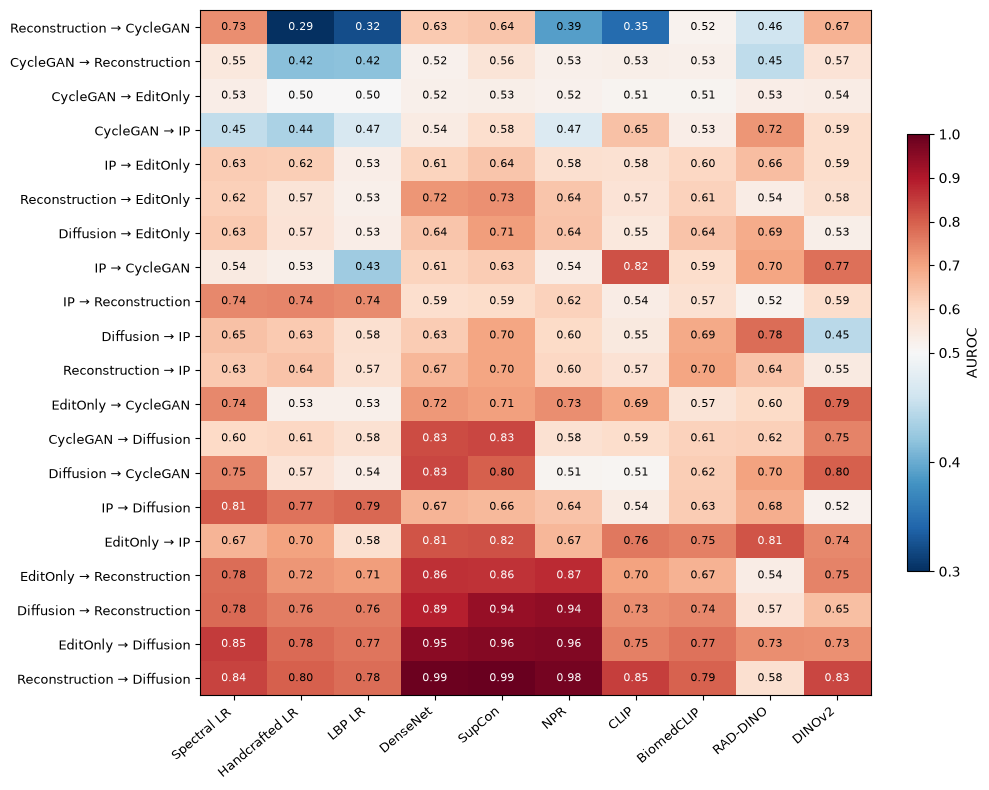

figures saved in /data/aa8624/thesis_2500/data/detection/results/figures


In [12]:
from matplotlib.colors import TwoSlopeNorm
plt.rcParams["pdf.fonttype"] = 42          # embed fonts in the PDFs

# ---------- load and prepare ----------
R = pd.read_csv(config.DET_RESULTS_CSV)
R = R.drop_duplicates(["experiment", "model", "seed", "role", "design"], keep="last")

FAMILIES = [f for f in config.FAMILY_SETS[config.ACTIVE_FAMILY_SET] if f in set(R.train_family)]
MODELS = [m for m in config.MODELS_TO_RUN if m in set(R.model)]
FIG_DIR = Path(config.DET_RESULTS_CSV).parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---------- display labels (names used in the paper) ----------
LAB_F = {"Diffusion_EditOnly": "EditOnly", "Diffusion_Reconstruction": "Reconstruction"}
LAB_M = {"cnn_densenet": "DenseNet", "supcon": "SupCon", "npr": "NPR",
         "spectral_lr": "Spectral LR", "lbp_lr": "LBP LR", "handcrafted_lr": "Handcrafted LR",
         "clip_frozen": "CLIP", "biomedclip_frozen": "BiomedCLIP",
         "rad_dino": "RAD-DINO", "dinov2_frozen": "DINOv2"}
fam_l = lambda f: LAB_F.get(f, f)
FAM_L = [fam_l(f) for f in FAMILIES]
MOD_L = [LAB_M.get(m, m) for m in MODELS]

# Seen family (test_in) fills the diagonal; unseen family (test_cross) fills the rest.
d = R[R.role.isin(["test_in", "test_cross"])].copy()
d["test_fam"] = d.test_family.where(d.role == "test_cross", d.train_family)

# Mean over seeds FIRST, so every detector counts once, whatever its number of seeds.
per_model = d.groupby(["train_family", "test_fam", "model"]).auroc.mean().reset_index()

# 0.5 (chance) is the centre colour: red = above chance, blue = below chance.
NORM = TwoSlopeNorm(vmin=0.3, vcenter=0.5, vmax=1.0)
CMAP = plt.get_cmap("RdBu_r")


def draw_heatmap(ax, values, row_labels, col_labels, fontsize=9, bold_diagonal=False, label_size=10):
    """Heatmap with the AUROC written in every cell; text colour follows the background."""
    im = ax.imshow(values, cmap=CMAP, norm=NORM, aspect="auto")
    ax.set_xticks(range(len(col_labels)))
    ax.set_xticklabels(col_labels, rotation=40, ha="right", fontsize=label_size)
    ax.set_yticks(range(len(row_labels)))
    ax.set_yticklabels(row_labels, fontsize=label_size)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values[i, j]
            if np.isnan(v):
                continue
            r, g, b, _ = CMAP(NORM(v))
            dark_bg = (0.299 * r + 0.587 * g + 0.114 * b) < 0.5
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=fontsize,
                    color="white" if dark_bg else "black",
                    fontweight="bold" if (bold_diagonal and i == j) else "normal")
    return im


# ---------- Figure 1: train family x test family, mean over detectors ----------
M = (per_model.groupby(["train_family", "test_fam"]).auroc.mean()      # each detector counts once
     .unstack("test_fam").reindex(index=FAMILIES, columns=FAMILIES))

fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = draw_heatmap(ax, M.values, FAM_L, FAM_L, fontsize=10, bold_diagonal=True, label_size=10)
ax.set_xlabel("Test family (unseen, except the diagonal)", fontsize=10)
ax.set_ylabel("Train family", fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046, label="AUROC")
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(FIG_DIR / f"cross_generator_family_matrix.{ext}", dpi=200, bbox_inches="tight")
plt.show()

# ---------- Figure 2: every transfer pair x every detector (worst pair at the top) ----------
cross = per_model[per_model.train_family != per_model.test_fam].copy()
cross["pair"] = cross.train_family.map(fam_l) + " → " + cross.test_fam.map(fam_l)
C = cross.pivot(index="pair", columns="model", values="auroc")[MODELS]
C = C.loc[C.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(10, 8))
im = draw_heatmap(ax, C.values, list(C.index), MOD_L, fontsize=8, label_size=9)
fig.colorbar(im, ax=ax, fraction=0.03, label="AUROC")
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(FIG_DIR / f"cross_generator_pairs_by_detector.{ext}", dpi=200, bbox_inches="tight")
plt.show()

print("figures saved in", FIG_DIR)

In [7]:
import pandas as pd, numpy as np, config

res = pd.read_csv(config.DET_RESULTS_CSV)
c = (res[res.role == "test_cross"]
     .groupby(["experiment", "model"]).auroc.mean().unstack())      # 20 pairs x 10 detectors (seeds averaged)

S = pd.DataFrame({
    "median": c.median(axis=1), "mean": c.mean(axis=1),
    "min": c.min(axis=1), "max": c.max(axis=1),
    "q25": c.quantile(.25, axis=1), "q75": c.quantile(.75, axis=1),
    "n>=0.70": (c >= 0.70).sum(axis=1), "n<0.50": (c < 0.50).sum(axis=1),
}).sort_values("median", ascending=False)
display(S.round(3))

TYPE = {"cnn_densenet": "networks", "supcon": "networks", "npr": "networks",
        "clip_frozen": "frozen", "biomedclip_frozen": "frozen", "rad_dino": "frozen",
        "dinov2_frozen": "frozen", "spectral_lr": "feature LR", "lbp_lr": "feature LR",
        "handcrafted_lr": "feature LR"}
T = c.T.groupby(TYPE).median().T                                   # median within each detector type
display(T.loc[S.index].round(3))

,median,mean,min,max,q25,q75,n>=0.70,n<0.50
experiment,,,,,,,,
Diffusion_Reconstruction->Diffusion,0.834,0.843,0.581,0.995,0.796,0.946,9,0
Diffusion_EditOnly->Diffusion,0.778,0.826,0.727,0.962,0.755,0.927,10,0
Diffusion->Diffusion_Reconstruction,0.757,0.775,0.566,0.941,0.734,0.863,8,0
Diffusion_EditOnly->IP,0.748,0.732,0.580,0.817,0.677,0.800,7,0
Diffusion_EditOnly->Diffusion_Reconstruction,0.734,0.747,0.539,0.874,0.702,0.840,7,0
Diffusion_EditOnly->CycleGAN,0.699,0.658,0.525,0.785,0.573,0.727,5,0
IP->Diffusion,0.667,0.671,0.521,0.807,0.630,0.748,3,0
Diffusion->CycleGAN,0.664,0.664,0.510,0.834,0.546,0.786,5,0
Diffusion_Reconstruction->IP,0.636,0.627,0.546,0.698,0.582,0.661,0,0


model,feature LR,frozen,networks
experiment,,,
Diffusion_Reconstruction->Diffusion,0.798,0.814,0.992
Diffusion_EditOnly->Diffusion,0.783,0.742,0.960
Diffusion->Diffusion_Reconstruction,0.758,0.690,0.937
Diffusion_EditOnly->IP,0.669,0.758,0.813
Diffusion_EditOnly->Diffusion_Reconstruction,0.719,0.686,0.863
Diffusion_EditOnly->CycleGAN,0.526,0.644,0.716
IP->Diffusion,0.788,0.583,0.663
Diffusion->CycleGAN,0.568,0.664,0.800
Diffusion_Reconstruction->IP,0.630,0.606,0.667


In [9]:
# bootstrapping with patient level split on the test data

import time
import numpy as np, pandas as pd, config
from sklearn.metrics import roc_auc_score

QUICK_TEST = False        # True = only 3 groups, to check it works. Set False for the full run.
B = 1000                 # bootstrap draws
OUT = "cross_generator_ci_patient_v1.csv"     # new file name; change folder if you want

# 1. load saved scores and patient IDs ---------------------------------------
P = pd.read_csv(config.DET_PREDICTIONS_CSV, dtype={"image_id": str})
print(f"[1] predictions loaded: {len(P):,} rows, roles = {sorted(P['role'].unique())}")

T = pd.read_csv(config.FORENSIC_FEATURE_CSV, dtype={"image_id": str, "subject_id": str},
                usecols=["image_id", "subject_id"]).drop_duplicates("image_id")
P = P.merge(T, on="image_id", how="left")
print(f"[2] patient IDs attached: {P['subject_id'].notna().mean():.1%} of rows have a subject_id")
assert P["subject_id"].notna().all(), "some images have no subject_id"

# 2. check the predictions file has one copy of each run ---------------------
key = ["experiment", "model", "seed", "role", "image_id"]
dups = P.duplicated(key).sum()
print(f"[3] duplicated (run, image) rows: {dups}  (should be 0)")
assert dups == 0, "predictions file has repeated runs; fix before continuing"

# 3. patient-level bootstrap for one group ------------------------------------
def patient_ci(g, B=1000, seed=0):
    rng = np.random.default_rng(seed)
    y, s = g["label"].to_numpy(), g["score"].to_numpy()
    members = [d.index.to_numpy() for _, d in g.groupby("subject_id")]
    vals = []
    for _ in range(B):
        idx = np.concatenate([members[i] for i in rng.integers(0, len(members), len(members))])
        if len(np.unique(y[idx])) == 2:
            vals.append(roc_auc_score(y[idx], s[idx]))
    return np.quantile(vals, [0.025, 0.975]), len(members), len(vals)

# 4. run over every experiment x model x seed x test role ---------------------
groups = list(P[P.role != "val"].groupby(["experiment", "model", "seed", "role"]))
if QUICK_TEST:
    groups = groups[:3]
print(f"[4] {len(groups)} groups to process, {B} draws each")

rows, t0 = [], time.time()
for k, ((e, m, sd, r), g) in enumerate(groups, 1):
    g = g.reset_index(drop=True)
    (lo, hi), n_pat, n_ok = patient_ci(g, B)
    auc = roc_auc_score(g["label"], g["score"])
    rows.append(dict(experiment=e, model=m, seed=sd, role=r, n_images=len(g), n_patients=n_pat,
                     auroc_check=auc, auroc_lo_pt=lo, auroc_hi_pt=hi))
    if k <= 3 or k % 20 == 0:
        el = time.time() - t0
        print(f"  [{k}/{len(groups)}] {e} | {m} | seed {sd} | {r}: AUROC {auc:.3f}, "
              f"patient-level CI {lo:.3f}-{hi:.3f}, images {len(g)}, patients {n_pat}, "
              f"valid draws {n_ok}/{B}, elapsed {el/60:.1f} min")

R = pd.DataFrame(rows)

# 5. compare with the existing results file -----------------------------------
old = pd.read_csv(config.DET_RESULTS_CSV)
old = old[old.role != "val"][["experiment", "model", "seed", "role", "auroc", "auroc_lo", "auroc_hi"]]
C = R.merge(old, on=["experiment", "model", "seed", "role"], how="left")
C["auroc_diff"] = (C["auroc_check"] - C["auroc"]).abs()
C["width_old"] = C["auroc_hi"] - C["auroc_lo"]
C["width_new"] = C["auroc_hi_pt"] - C["auroc_lo_pt"]
print(f"[5] max |AUROC recomputed - AUROC in results file| = {C['auroc_diff'].max():.2e}  (should be ~0)")
print(f"    mean CI width: image-level {C['width_old'].mean():.3f} vs patient-level {C['width_new'].mean():.3f}")
print(f"    patient-level interval is wider in {(C['width_new'] > C['width_old']).mean():.0%} of groups")

C.to_csv(OUT, index=False)
print(f"[6] saved {len(C)} rows -> {OUT}")

[1] predictions loaded: 958,464 rows, roles = ['test_cross', 'test_in', 'val']
[2] patient IDs attached: 100.0% of rows have a subject_id
[3] duplicated (run, image) rows: 0  (should be 0)
[4] 640 groups to process, 1000 draws each
  [1/640] CycleGAN->Diffusion | biomedclip_frozen | seed 42 | test_cross: AUROC 0.613, patient-level CI 0.598-0.631, images 996, patients 201, valid draws 1000/1000, elapsed 0.0 min
  [2/640] CycleGAN->Diffusion | biomedclip_frozen | seed 42 | test_in: AUROC 0.840, patient-level CI 0.813-0.869, images 1000, patients 201, valid draws 1000/1000, elapsed 0.0 min
  [3/640] CycleGAN->Diffusion | clip_frozen | seed 42 | test_cross: AUROC 0.589, patient-level CI 0.571-0.607, images 996, patients 201, valid draws 1000/1000, elapsed 0.1 min
  [20/640] CycleGAN->Diffusion | npr | seed 43 | test_in: AUROC 1.000, patient-level CI 0.999-1.000, images 1000, patients 201, valid draws 1000/1000, elapsed 0.4 min
  [40/640] CycleGAN->Diffusion_EditOnly | cnn_densenet | seed 4

In [8]:
C = pd.read_csv("cross_generator_ci_patient_v1.csv")
x = C[C.role == "test_cross"]
print("lower bound > 0.5 :", (x.auroc_lo > 0.5).sum(), "image-level vs", (x.auroc_lo_pt > 0.5).sum(), "patient-level")
print("AUROC>=0.70 & lower>0.5:", ((x.auroc >= .70) & (x.auroc_lo > .5)).sum(), "vs", ((x.auroc >= .70) & (x.auroc_lo_pt > .5)).sum())

lower bound > 0.5 : 262 image-level vs 285 patient-level
AUROC>=0.70 & lower>0.5: 115 vs 115


#### run against all 42 features

In [8]:
%run cross_all42.py

test_family        IP  CycleGAN  Diffusion  EditOnly  Reconstruction
train_family                                                        
IP              0.732     0.628      0.797     0.635           0.746
CycleGAN        0.546     0.994      0.694     0.557           0.536
Diffusion       0.645     0.735      0.902     0.605           0.816
EditOnly        0.690     0.845      0.824     0.651           0.761
Reconstruction  0.636     0.592      0.855     0.596           0.839

mean in-family : 0.824
mean unseen    : 0.687
saved -> /data/aa8624/thesis_2500/data/detection/results/cross_generator_handcrafted_all42.csv

                                                    top_k  all42   diff
train_family             test_family                                  
CycleGAN                 CycleGAN                  0.980  0.994  0.014
                         Diffusion                 0.605  0.694  0.089
                         Diffusion_EditOnly        0.502    NaN    NaN
                  

In [11]:
import pandas as pd, config
R = pd.read_csv(config.DET_RESULTS_DIR / "cross_generator_handcrafted_all42.csv")
old = pd.read_csv(config.DET_RESULTS_CSV)
m = {"Diffusion_EditOnly": "EditOnly", "Diffusion_Reconstruction": "Reconstruction"}
old["train_family"] = old["train_family"].replace(m)
old["test_family"] = old["test_family"].replace(m)
o = old[old["model"] == "handcrafted_lr"].groupby(["train_family", "test_family"])["auroc"].mean()
order = ["IP", "CycleGAN", "Diffusion", "EditOnly", "Reconstruction"]
n = R.set_index(["train_family", "test_family"])["auroc"]
for a in order:
    cells = []
    for b in order:
        d = n[(a, b)] - o[(a, b)]
        v = f"{n[(a, b)]:.3f} ({'+' if d >= 0 else '$-$'}{abs(d):.3f})"
        cells.append(f"\\textbf{{{v.split(' ')[0]}}} {v.split(' ',1)[1]}" if a == b else v)
    print(f"{a:<14} & " + " & ".join(cells) + r" \\")

IP             & \textbf{0.732} (+0.018) & 0.628 (+0.097) & 0.797 (+0.028) & 0.635 (+0.010) & 0.746 (+0.003) \\
CycleGAN       & 0.546 (+0.110) & \textbf{0.994} (+0.014) & 0.694 (+0.089) & 0.557 (+0.056) & 0.536 (+0.118) \\
Diffusion      & 0.645 (+0.015) & 0.735 (+0.167) & \textbf{0.902} (+0.050) & 0.605 (+0.036) & 0.816 (+0.058) \\
EditOnly       & 0.690 ($-$0.010) & 0.845 (+0.320) & 0.824 (+0.040) & \textbf{0.651} (+0.037) & 0.761 (+0.042) \\
Reconstruction & 0.636 ($-$0.006) & 0.592 (+0.302) & 0.855 (+0.058) & 0.596 (+0.030) & \textbf{0.839} (+0.033) \\


In [12]:
import pandas as pd, numpy as np, config
d = pd.read_csv(config.DET_RESULTS_CSV)
print(d.columns.tolist())                       # check: model, seed, train_family, test_family, auroc

m = {"Diffusion_EditOnly": "EditOnly", "Diffusion_Reconstruction": "Reconstruction"}
d["train_family"] = d["train_family"].replace(m)
d["test_family"]  = d["test_family"].replace(m)
print(d["model"].unique())                      # should be exactly your ten detectors, 5 families
print(sorted(d["train_family"].unique()))

key = ["model", "train_family", "test_family"]
per = d.groupby(key, as_index=False)["auroc"].mean()      # seed-averaged value per detector x pair
un  = per[per.train_family != per.test_family]

print("n unseen values:", len(un), "(expect 200)")
print("AUROC >= 0.70:", int((un.auroc >= 0.70).sum()))
print("AUROC >= 0.90:", int((un.auroc >= 0.90).sum()))
print("AUROC < 0.50 :", int((un.auroc < 0.50).sum()))
print("minimum:", un.loc[un.auroc.idxmin(), key + ["auroc"]].to_dict())
print("mean in-family:", round(per[per.train_family == per.test_family].auroc.mean(), 3),
      "| mean unseen:", round(un.auroc.mean(), 3))

# seed standard deviation (networks only = models with more than one seed)
s = d.groupby(key)["auroc"].agg(sd="std", n="count").reset_index()   # sample SD (ddof=1)
s = s[s.n > 1]
print("networks:", s["model"].unique())
print("all 25 pairs: mean SD", round(s.sd.mean(), 3), "max", round(s.sd.max(), 3))
u = s[s.train_family != s.test_family]
print("unseen pairs only: mean SD", round(u.sd.mean(), 3), "max", round(u.sd.max(), 3))

['experiment', 'train_family', 'test_family', 'model', 'seed', 'role', 'design', 'fit_seconds', 'n', 'n_real', 'n_synth', 'prevalence', 'threshold', 'auroc', 'auprc', 'tn', 'fp', 'fn', 'tp', 'recall', 'specificity', 'precision', 'f1', 'accuracy', 'balanced_acc', 'balanced_acc_oracle', 'auroc_lo', 'auroc_hi', 'auprc_lo', 'auprc_hi']
<StringArray>
['spectral_lr', 'handcrafted_lr', 'lbp_lr', 'cnn_densenet', 'supcon', 'npr', 'clip_frozen', 'biomedclip_frozen', 'rad_dino', 'dinov2_frozen']
Length: 10, dtype: str
['CycleGAN', 'Diffusion', 'EditOnly', 'IP', 'Reconstruction']
n unseen values: 200 (expect 200)
AUROC >= 0.70: 68
AUROC >= 0.90: 8
AUROC < 0.50 : 14
minimum: {'model': 'handcrafted_lr', 'train_family': 'Reconstruction', 'test_family': 'CycleGAN', 'auroc': 0.289832}
mean in-family: 0.866 | mean unseen: 0.648
networks: <StringArray>
['biomedclip_frozen', 'clip_frozen', 'cnn_densenet', 'dinov2_frozen', 'handcrafted_lr', 'lbp_lr', 'npr', 'rad_dino', 'spectral_lr', 'supcon']
Length: 10, 

In [13]:
print(d[["experiment","role","design"]].drop_duplicates().to_string())
print(d.groupby("model").agg(seeds=("seed","nunique"), rows=("auroc","size")))

nets = ["cnn_densenet", "supcon", "npr"]
k2 = ["model","experiment","role","design","train_family","test_family"]
s = (d[d.model.isin(nets)].groupby(k2)["auroc"]
       .agg(sd="std", n="count").reset_index())
print(s.n.value_counts())                     # should be 3 (seeds 42, 43, 44) throughout
u = s[s.train_family != s.test_family]
print("networks, unseen pairs: mean SD", round(u.sd.mean(), 3), "max", round(u.sd.max(), 3))
print("networks, all pairs   : mean SD", round(s.sd.mean(), 3), "max", round(s.sd.max(), 3))

                                       experiment        role                     design
0                                    IP->CycleGAN         val  c9cd343c9d86-youden-b1000
1                                    IP->CycleGAN     test_in  c9cd343c9d86-youden-b1000
2                                    IP->CycleGAN  test_cross  c9cd343c9d86-youden-b1000
48                                  IP->Diffusion         val  d2335cd5d060-youden-b1000
49                                  IP->Diffusion     test_in  d2335cd5d060-youden-b1000
50                                  IP->Diffusion  test_cross  d2335cd5d060-youden-b1000
96                         IP->Diffusion_EditOnly         val  bb936ceef383-youden-b1000
97                         IP->Diffusion_EditOnly     test_in  bb936ceef383-youden-b1000
98                         IP->Diffusion_EditOnly  test_cross  bb936ceef383-youden-b1000
144                  IP->Diffusion_Reconstruction         val  51c71f55e985-youden-b1000
145                  

In [14]:
t_in = d[d.role == "test_in"].groupby(["model","train_family"], as_index=False)["auroc"].mean()
v_in = d[d.role == "val"].groupby(["model","train_family"], as_index=False)["auroc"].mean()
t_cr = d[d.role == "test_cross"].groupby(["model","train_family","test_family"], as_index=False)["auroc"].mean()
print("test_in mean :", round(t_in.auroc.mean(), 3))
print("val mean     :", round(v_in.auroc.mean(), 3))
print("test_cross   :", round(t_cr.auroc.mean(), 3), "n =", len(t_cr))
print(t_in.groupby("model").auroc.mean().round(3))                # compare with the In-family column of Table 1
print(t_in.groupby("train_family").auroc.mean().round(3))         # compare with the matrix diagonal

test_in mean : 0.866
val mean     : 0.866
test_cross   : 0.648 n = 200
model
biomedclip_frozen    0.806
clip_frozen          0.888
cnn_densenet         0.993
dinov2_frozen        0.903
handcrafted_lr       0.795
lbp_lr               0.752
npr                  0.962
rad_dino             0.797
spectral_lr          0.772
supcon               0.994
Name: auroc, dtype: float64
train_family
CycleGAN          0.949
Diffusion         0.912
EditOnly          0.741
IP                0.865
Reconstruction    0.864
Name: auroc, dtype: float64


In [7]:
import pandas as pd, numpy as np, config
d = pd.read_csv(config.DET_RESULTS_CSV)
m = {"Diffusion_EditOnly": "EditOnly", "Diffusion_Reconstruction": "Reconstruction"}
d["train_family"] = d["train_family"].replace(m); d["test_family"] = d["test_family"].replace(m)

X = (d[d.role == "test_cross"]
     .groupby(["model", "train_family", "test_family"], as_index=False)["auroc"].mean())   # seed-averaged
FEAT = ["spectral_lr", "lbp_lr", "handcrafted_lr"]
NET  = ["cnn_densenet", "supcon", "npr"]
FROZ = ["clip_frozen", "biomedclip_frozen", "rad_dino", "dinov2_frozen"]
def cell(models, a, b):
    return X[X.model.isin(models) & (X.train_family == a) & (X.test_family == b)].auroc.mean()

print("feature LR  CycleGAN->IP            :", round(cell(FEAT, "CycleGAN", "IP"), 3))
print("feature LR  CycleGAN->Reconstruction:", round(cell(FEAT, "CycleGAN", "Reconstruction"), 3))
print("feature LR  Reconstruction->CycleGAN:", round(cell(FEAT, "Reconstruction", "CycleGAN"), 3))
print("IP->Diffusion       feature LR vs networks:", round(cell(FEAT, "IP", "Diffusion"), 3), round(cell(NET, "IP", "Diffusion"), 3))
print("IP->Reconstruction  feature LR vs networks:", round(cell(FEAT, "IP", "Reconstruction"), 3), round(cell(NET, "IP", "Reconstruction"), 3))
print("frozen encoders IP->CycleGAN        :", round(cell(FROZ, "IP", "CycleGAN"), 3))
print("CycleGAN-trained networks -> Diffusion:", round(cell(NET, "CycleGAN", "Diffusion"), 3))
r = X[(X.train_family == "Reconstruction") & (X.test_family == "CycleGAN")].auroc
print("Reconstruction->CycleGAN range      :", round(r.min(), 3), round(r.max(), 3))
c = X[(X.train_family == "CycleGAN") & (X.test_family == "EditOnly")].auroc
print("CycleGAN->EditOnly range            :", round(c.min(), 3), round(c.max(), 3))

low = X[X.auroc < 0.5]
print("cells below 0.5:", len(low), "| involving CycleGAN:",
      int(((low.train_family == "CycleGAN") | (low.test_family == "CycleGAN")).sum()))

rel = {("Diffusion","EditOnly"), ("Diffusion","Reconstruction"), ("EditOnly","Diffusion"),
       ("EditOnly","Reconstruction"), ("Reconstruction","Diffusion"), ("Reconstruction","EditOnly")}
isrel = X.apply(lambda r: (r.train_family, r.test_family) in rel, axis=1)
print("mean unseen, all 200 cells         :", round(X.auroc.mean(), 3))
print("mean unseen, excluding related pairs:", round(X[~isrel].auroc.mean(), 3))

feature LR  CycleGAN->IP            : 0.452
feature LR  CycleGAN->Reconstruction: 0.462
feature LR  Reconstruction->CycleGAN: 0.449
IP->Diffusion       feature LR vs networks: 0.788 0.658
IP->Reconstruction  feature LR vs networks: 0.739 0.598
frozen encoders IP->CycleGAN        : 0.719
CycleGAN-trained networks -> Diffusion: 0.746
Reconstruction->CycleGAN range      : 0.29 0.734
CycleGAN->EditOnly range            : 0.5 0.536
cells below 0.5: 14 | involving CycleGAN: 13
mean unseen, all 200 cells         : 0.648
mean unseen, excluding related pairs: 0.611


#### Which detector typs is the best

In [10]:
FEAT = ["spectral_lr", "lbp_lr", "handcrafted_lr"]
NET  = ["cnn_densenet", "supcon", "npr"]
FROZ = ["clip_frozen", "biomedclip_frozen", "rad_dino", "dinov2_frozen"]
typ = {**{m: "feature LR" for m in FEAT}, **{m: "network" for m in NET}, **{m: "frozen" for m in FROZ}}
X["type"] = X["model"].map(typ)

T = (X.groupby(["train_family", "test_family", "type"], as_index=False)["auroc"].mean()
       .pivot(index=["train_family", "test_family"], columns="type", values="auroc"))
T["best"] = T.idxmax(axis=1)
print(T.round(3).to_string())
print("\npairs where each type is best:\n", T["best"].value_counts())
print("max network value on any single detector-pair:",
      round(X[X.type == "network"].auroc.max(), 3))

type                           feature LR  frozen  network        best
train_family   test_family                                            
CycleGAN       Diffusion            0.594   0.642    0.746     network
               EditOnly             0.511   0.524    0.525     network
               IP                   0.452   0.622    0.532      frozen
               Reconstruction       0.462   0.518    0.537     network
Diffusion      CycleGAN             0.617   0.659    0.716     network
               EditOnly             0.578   0.604    0.663     network
               IP                   0.619   0.617    0.641     network
               Reconstruction       0.766   0.672    0.922     network
EditOnly       CycleGAN             0.597   0.660    0.718     network
               Diffusion            0.801   0.746    0.958     network
               IP                   0.650   0.768    0.765      frozen
               Reconstruction       0.736   0.665    0.866     network
IP    

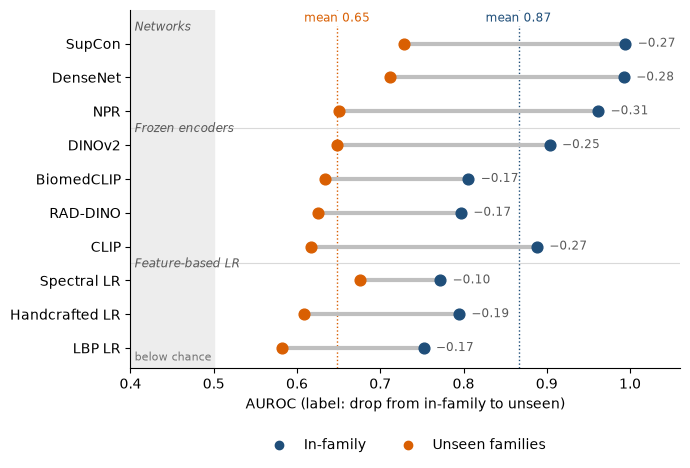

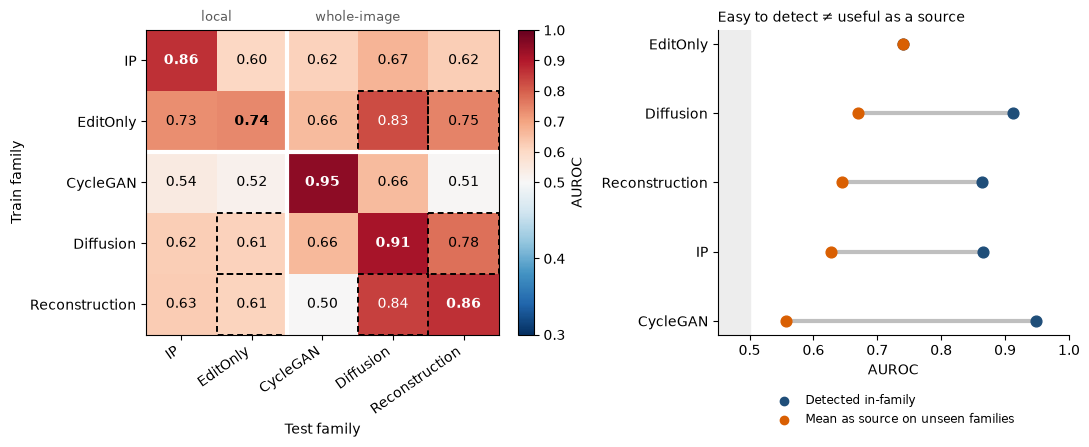

In [16]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
plt.rcParams.update({"pdf.fonttype": 42, "font.size": 10})

d = per_model.rename(columns={"train_family":"src","test_fam":"tgt","model":"model_key","auroc":"auc"})[
    ["model_key","src","tgt","auc"]].copy()
FAM = {"Diffusion_EditOnly":"EditOnly","Diffusion_Reconstruction":"Reconstruction"}
d["src"] = d.src.replace(FAM); d["tgt"] = d.tgt.replace(FAM)

KEYMAP = [("biomedclip","BiomedCLIP"),("raddino","RAD-DINO"),("rad_dino","RAD-DINO"),("dinov2","DINOv2"),
          ("clip","CLIP"),("densenet","DenseNet"),("supcon","SupCon"),("npr","NPR"),("lbp","LBP LR"),
          ("spectral","Spectral LR"),("handcrafted","Handcrafted LR")]
disp = lambda k: next((v for key,v in KEYMAP if key in str(k).lower()), None)
d["model"] = d.model_key.map(disp)
assert d.model.notna().all(), sorted(d.loc[d.model.isna(),"model_key"].unique())

CAT = {"SupCon":"Networks","DenseNet":"Networks","NPR":"Networks",
       "DINOv2":"Frozen encoders","BiomedCLIP":"Frozen encoders","RAD-DINO":"Frozen encoders","CLIP":"Frozen encoders",
       "Spectral LR":"Feature-based LR","Handcrafted LR":"Feature-based LR","LBP LR":"Feature-based LR"}
GROUPS = ["Networks","Frozen encoders","Feature-based LR"]
BLUE, ORANGE = "#1f4e79", "#d95f02"

# ---------- Figure A ----------
infam  = d[d.src==d.tgt].groupby("model").auc.mean()
unseen = d[d.src!=d.tgt].groupby("model").auc.mean()
rows = []
for g in GROUPS:
    rows += sorted([m for m in CAT if CAT[m]==g], key=lambda m: -unseen[m])
fig, ax = plt.subplots(figsize=(7, 4.8))
y = np.arange(len(rows))[::-1]
ax.axvspan(0.40, 0.5, color="0.93", zorder=0)
ax.axvline(infam.mean(),  color=BLUE,   lw=1, ls=":", zorder=1)
ax.axvline(unseen.mean(), color=ORANGE, lw=1, ls=":", zorder=1)
for yi, m in zip(y, rows):
    ax.plot([unseen[m], infam[m]], [yi, yi], color="0.75", lw=3, zorder=2, solid_capstyle="round")
    ax.scatter(infam[m],  yi, color=BLUE,   s=60, zorder=3)
    ax.scatter(unseen[m], yi, color=ORANGE, s=60, zorder=3)
    ax.text(infam[m]+0.015, yi, f"−{infam[m]-unseen[m]:.2f}", va="center", fontsize=8.5, color="0.35")
ax.text(infam.mean(),  len(rows)-0.35, f"mean {infam.mean():.2f}",  color=BLUE,   ha="center", fontsize=8.5, bbox=dict(fc="white",ec="none",pad=1))
ax.text(unseen.mean(), len(rows)-0.35, f"mean {unseen.mean():.2f}", color=ORANGE, ha="center", fontsize=8.5, bbox=dict(fc="white",ec="none",pad=1))
ax.text(0.405, -0.45, "below chance", fontsize=8, color="0.45", va="bottom")
ax.set_yticks(y); ax.set_yticklabels(rows)
start = 0
for g in GROUPS:
    n = sum(CAT[m]==g for m in rows)
    if start > 0: ax.axhline((y[start-1]+y[start])/2, color="0.85", lw=0.8)
    ax.text(0.405, y[start]+0.3, g, fontsize=8.5, color="0.35", style="italic", va="bottom")
    start += n
ax.set_xlim(0.40, 1.06); ax.set_ylim(-0.6, len(rows)-0.0)
ax.set_xlabel("AUROC (label: drop from in-family to unseen)")
ax.scatter([],[],color=BLUE,label="In-family"); ax.scatter([],[],color=ORANGE,label="Unseen families")
ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.16), ncol=2, frameon=False)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR/"cross_generator_gap_by_detector.pdf", bbox_inches="tight")
plt.show()

# ---------- Figure B: matrix + in-family vs as-source ----------
O = ["IP","EditOnly","CycleGAN","Diffusion","Reconstruction"]
M = d.groupby(["src","tgt"]).auc.mean().unstack().reindex(index=O, columns=O).values
assert not np.isnan(M).any(), "family names do not match O"
NORM = TwoSlopeNorm(vmin=0.3, vcenter=0.5, vmax=1.0); CMAP = plt.get_cmap("RdBu_r")
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios":[1,0.9]})
ax = axs[0]
im = ax.imshow(M, cmap=CMAP, norm=NORM, aspect="auto")
ax.set_xticks(range(5)); ax.set_xticklabels(O, rotation=35, ha="right")
ax.set_yticks(range(5)); ax.set_yticklabels(O)
for i in range(5):
    for j in range(5):
        r,g,b,_ = CMAP(NORM(M[i,j])); dark = (0.299*r+0.587*g+0.114*b) < 0.5
        ax.text(j,i,f"{M[i,j]:.2f}",ha="center",va="center",color="white" if dark else "black",
                fontweight="bold" if i==j else "normal")
ax.axvline(1.5,color="white",lw=3); ax.axhline(1.5,color="white",lw=3)
for a,b in [("Diffusion","EditOnly"),("Diffusion","Reconstruction"),("EditOnly","Diffusion"),
            ("EditOnly","Reconstruction"),("Reconstruction","Diffusion"),("Reconstruction","EditOnly")]:
    i,j = O.index(a), O.index(b)
    ax.add_patch(Rectangle((j-0.5,i-0.5),1,1,fill=False,ec="k",lw=1.4,ls=(0,(3,2))))
ax.set_xlabel("Test family"); ax.set_ylabel("Train family")
ax.text(0.2,1.03,"local",transform=ax.transAxes,ha="center",fontsize=9,color="0.35")
ax.text(0.6,1.03,"whole-image",transform=ax.transAxes,ha="center",fontsize=9,color="0.35")
fig.colorbar(im, ax=ax, fraction=0.046, label="AUROC")

ax = axs[1]
inf_f = pd.Series({f: M[O.index(f),O.index(f)] for f in O})
src_f = pd.Series({f: np.delete(M[O.index(f)], O.index(f)).mean() for f in O})
order = src_f.sort_values(ascending=False).index.tolist()
yy = np.arange(len(order))[::-1]
ax.axvspan(0.4,0.5,color="0.93",zorder=0)
for yi,f in zip(yy,order):
    ax.plot([src_f[f],inf_f[f]],[yi,yi],color="0.75",lw=3,zorder=2,solid_capstyle="round")
    ax.scatter(inf_f[f], yi,color=BLUE,  s=60,zorder=3)
    ax.scatter(src_f[f], yi,color=ORANGE,s=60,zorder=3)
ax.set_yticks(yy); ax.set_yticklabels(order)
ax.set_xlim(0.45,1.0); ax.set_xlabel("AUROC")
ax.scatter([],[],color=BLUE,label="Detected in-family"); ax.scatter([],[],color=ORANGE,label="Mean as source on unseen families")
ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.16), ncol=1, frameon=False, fontsize=8.5)
ax.set_title("Easy to detect ≠ useful as a source", fontsize=10, loc="left")
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR/"cross_generator_matrix_asymmetry.pdf", bbox_inches="tight")
plt.show()

## Appendix section 

#### Parameter checks for the detector

In [10]:
import time, numpy as np, pandas as pd, config
from pathlib import Path
from sklearn.metrics import roc_auc_score
from stage4_experiments.splits import build_experiments
from stage4_experiments import runner
from stage5_models import get_detector_class
from utils.common import seed_everything

OUT = Path(config.DET_RESULTS_DIR) / "check_hyperparams.csv"     # new file only
SEED = 42
SOURCES = None            # None = all five source families; or e.g. ["IP", "CycleGAN", "Diffusion"] to save time

exps = build_experiments(runner.load_modelling_table(check_files=False))
by_source = {}
for e in exps:
    by_source.setdefault(e.train_family, []).append(e)
if SOURCES:
    by_source = {k: v for k, v in by_source.items() if k in SOURCES}

# ---- the grids: edit these ----
GRIDS = {
    "cnn_densenet": [dict(CNN_LEARNING_RATE=lr) for lr in (5e-5, 1e-4, 2e-4)],
    "supcon": [dict(SUPCON_LEARNING_RATE=lr, SUPCON_TEMPERATURE=t)
               for lr in (1e-4, 2e-4) for t in (0.07, 0.1)],
}
RUN = ["cnn_densenet"]     # start with DenseNet only; add "supcon" after you see how long one fit takes

def key(model, params, source):
    return (model, str(sorted(params.items())), source)

done = set()
if OUT.exists():
    d = pd.read_csv(OUT)
    done = {(r.model, r.params, r.source) for r in d.itertuples()}

t0 = time.time()
for model in RUN:
    cls = get_detector_class(model)
    for params in GRIDS[model]:
        for source, exs in by_source.items():
            k = key(model, params, source)
            if k in done:
                print("skip", k); continue
            old = {n: getattr(config, n) for n in params}
            for n, v in params.items():
                setattr(config, n, v)                          # the detectors read config at fit time
            try:
                seed_everything(SEED)
                det = cls(seed=SEED).fit(exs[0].train_df, exs[0].val_df)       # source train, source val
                cross = [roc_auc_score(e.test_cross_df["label"].to_numpy(),
                                       det.predict_scores(e.test_cross_df)) for e in exs]
                row = dict(model=model, params=str(sorted(params.items())), source=source,
                           val_auroc=det.val_auroc,              # USE THIS to choose
                           best_epoch=det.best_epoch,
                           cross_auroc_mean=float(np.mean(cross)),  # sensitivity only, never for choosing
                           minutes=round((time.time() - t0) / 60, 1))
            finally:
                for n, v in old.items():
                    setattr(config, n, v)
            pd.DataFrame([row]).to_csv(OUT, mode="a", header=not OUT.exists(), index=False)
            print(model, params, source, f"val={row['val_auroc']:.3f} best_epoch={row['best_epoch']} "
                  f"cross={row['cross_auroc_mean']:.3f} ({row['minutes']} min)")

res = pd.read_csv(OUT)
print(res.groupby(["model", "params"])[["val_auroc", "cross_auroc_mean", "best_epoch"]].mean().round(3))

skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 5e-05)]", 'IP')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 5e-05)]", 'CycleGAN')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 5e-05)]", 'Diffusion')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 5e-05)]", 'Diffusion_EditOnly')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 5e-05)]", 'Diffusion_Reconstruction')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0001)]", 'IP')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0001)]", 'CycleGAN')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0001)]", 'Diffusion')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0001)]", 'Diffusion_EditOnly')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0001)]", 'Diffusion_Reconstruction')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0002)]", 'IP')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0002)]", 'CycleGAN')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0002)]", 'Diffusion')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0002)]", 'Diffusion_Edi

In [12]:
import time, json, numpy as np, pandas as pd, config
from pathlib import Path
from sklearn.metrics import roc_auc_score
from stage4_experiments.splits import build_experiments
from stage4_experiments import runner
from stage5_models import get_detector_class
from utils.common import seed_everything

OUT = Path(config.DET_RESULTS_DIR) / "check_hyperparams.csv"      # new file; main results untouched
SEED = 42
exps = build_experiments(runner.load_modelling_table(check_files=False))
by_source = {}
for e in exps:
    by_source.setdefault(e.train_family, []).append(e)

FAST3 = ["IP", "Diffusion", "Diffusion_Reconstruction"]            # the three quickest SupCon sources
HARD2 = ["Diffusion_EditOnly", "Diffusion_Reconstruction"]         # sources where the epoch cap was reached

# Check the config names exist before a long run
needed = ["CNN_LEARNING_RATE", "CNN_EPOCHS", "CNN_BATCH_SIZE", "CNN_WEIGHT_DECAY",
          "CNN_EARLY_STOP_PATIENCE", "CNN_AUG_HFLIP",
          "NPR_EPOCHS", "NPR_LEARNING_RATE", "NPR_BATCH_SIZE", "NPR_WEIGHT_DECAY",
          "NPR_EARLY_STOP_PATIENCE", "NPR_AUG_HFLIP",
          "SUPCON_TEMPERATURE", "SUPCON_LEARNING_RATE", "SUPCON_EPOCHS",
          "SUPCON_BATCH_SIZE", "SUPCON_WEIGHT_DECAY"]
missing = [n for n in needed if not hasattr(config, n)]
assert not missing, f"config names not found: {missing}  (check with: grep -n 'EPOCHS\\|LEARNING\\|BATCH\\|DECAY\\|PATIENCE\\|HFLIP' config.py)"

JOBS = [   # (model, settings to change, source families or None = all five)
    ("cnn_densenet", dict(CNN_LEARNING_RATE=5e-5), None),          # done earlier -> skipped
    ("cnn_densenet", dict(CNN_LEARNING_RATE=1e-4), None),          # done earlier -> skipped
    ("cnn_densenet", dict(CNN_LEARNING_RATE=2e-4), None),          # done earlier -> skipped
    ("cnn_densenet", dict(CNN_EPOCHS=30), HARD2),
    ("supcon", dict(SUPCON_TEMPERATURE=0.1), FAST3),
    ("supcon", dict(SUPCON_LEARNING_RATE=2e-4), FAST3),
    ("npr",    dict(NPR_EPOCHS=60), ["Diffusion_EditOnly"]),
    ("supcon", dict(SUPCON_EPOCHS=60), HARD2),
    ("npr",    dict(NPR_LEARNING_RATE=1e-4), HARD2),
    # --- remaining sensitivity checks ---
    ("cnn_densenet", dict(CNN_BATCH_SIZE=16), HARD2),               # done
    ("cnn_densenet", dict(CNN_BATCH_SIZE=64), HARD2),               # done
    ("cnn_densenet", dict(CNN_WEIGHT_DECAY=0.0), HARD2),            # done
    ("cnn_densenet", dict(CNN_WEIGHT_DECAY=1e-3), HARD2),           # done
    ("cnn_densenet", dict(CNN_EARLY_STOP_PATIENCE=8), HARD2),
    ("cnn_densenet", dict(CNN_AUG_HFLIP=False), HARD2),
    ("npr", dict(NPR_BATCH_SIZE=16), HARD2),
    ("npr", dict(NPR_WEIGHT_DECAY=1e-4), HARD2),
    ("npr", dict(NPR_EARLY_STOP_PATIENCE=10), HARD2),
    ("npr", dict(NPR_AUG_HFLIP=False), HARD2),
    ("supcon", dict(SUPCON_BATCH_SIZE=32), HARD2),
    ("supcon", dict(SUPCON_WEIGHT_DECAY=0.0), HARD2),
    ("supcon", dict(SUPCON_WEIGHT_DECAY=1e-3), HARD2),
]

def saved_default(model, source):
    """Default setting of the main run (seed 42), read from the saved model info and results."""
    meta = json.load(open(runner.model_dir(by_source[source][0], model, SEED) / "meta.json"))["info"]
    r = pd.read_csv(config.DET_RESULTS_CSV)
    r = r[(r.model == model) & (r.seed == SEED) & (r.role == "test_cross") & (r.train_family == source)]
    return dict(model=model, params="DEFAULT (main run)", source=source, val_auroc=meta["source_val_auroc"],
                best_epoch=meta.get("best_epoch"), cross_auroc_mean=float(r.auroc.mean()), minutes=0)

def append(row):
    pd.DataFrame([row]).to_csv(OUT, mode="a", header=not OUT.exists(), index=False)

done = set()
if OUT.exists():
    d = pd.read_csv(OUT); done = {(r.model, r.params, r.source) for r in d.itertuples()}

# 1) the default settings, taken from the main run, for the sources used below
for model, params, sources in JOBS:
    for s in (sources or list(by_source)):
        k = (model, "DEFAULT (main run)", s)
        if k not in done:
            try:
                append(saved_default(model, s)); done.add(k)
            except Exception as ex:
                print("no saved default for", model, s, "->", repr(ex)[:80])

# 2) the new fits (finished ones are skipped)
t0 = time.time()
for model, params, sources in JOBS:
    cls = get_detector_class(model)
    for source in (sources or list(by_source)):
        exs = by_source[source]
        k = (model, str(sorted(params.items())), source)
        if k in done:
            print("skip", k); continue
        old = {n: getattr(config, n) for n in params}
        for n, v in params.items():
            setattr(config, n, v)                                   # detectors read config at fit time
        try:
            seed_everything(SEED)
            det = cls(seed=SEED).fit(exs[0].train_df, exs[0].val_df)       # source train, source val only
            cross = [roc_auc_score(e.test_cross_df["label"].to_numpy(),
                                   det.predict_scores(e.test_cross_df)) for e in exs]
            row = dict(model=model, params=str(sorted(params.items())), source=source,
                       val_auroc=det.val_auroc,                      # use THIS to choose
                       best_epoch=det.best_epoch,
                       cross_auroc_mean=float(np.mean(cross)),       # sensitivity only, never for choosing
                       minutes=round((time.time() - t0) / 60, 1))
        finally:
            for n, v in old.items():
                setattr(config, n, v)
        append(row); done.add(k)
        print(model, params, source, f"val={row['val_auroc']:.4f} best_epoch={row['best_epoch']} "
              f"cross={row['cross_auroc_mean']:.3f} ({row['minutes']} min)")

# 3) summary: one table per quantity, rows = setting, columns = source family
res = pd.read_csv(OUT)
for col in ("val_auroc", "cross_auroc_mean", "best_epoch"):
    print(f"\n{col}")
    print(res.pivot_table(index=["model", "params"], columns="source", values=col).round(3).to_string())

skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 5e-05)]", 'IP')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 5e-05)]", 'CycleGAN')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 5e-05)]", 'Diffusion')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 5e-05)]", 'Diffusion_EditOnly')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 5e-05)]", 'Diffusion_Reconstruction')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0001)]", 'IP')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0001)]", 'CycleGAN')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0001)]", 'Diffusion')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0001)]", 'Diffusion_EditOnly')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0001)]", 'Diffusion_Reconstruction')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0002)]", 'IP')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0002)]", 'CycleGAN')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0002)]", 'Diffusion')
skip ('cnn_densenet', "[('CNN_LEARNING_RATE', 0.0002)]", 'Diffusion_Edi

In [13]:
import json, glob, pandas as pd
rows = []
for f in glob.glob(str(config.DET_MODEL_DIR / "*" / "*_seed*" / "meta.json")):
    m = json.load(open(f))
    if m["model"] in ("cnn_densenet", "supcon", "npr"):
        rows.append(dict(model=m["model"], experiment=m["experiment"], seed=m["seed"],
                         best_epoch=m["info"].get("best_epoch"),
                         source_val_auroc=m["info"].get("source_val_auroc")))
df = pd.DataFrame(rows).sort_values(["model", "experiment", "seed"])

print(df.groupby("model").best_epoch.describe().round(1))                 # summary per network
print(df.groupby("model").best_epoch.apply(lambda s: round((s == s.max()).mean(), 2)))   # share at the max epoch
print(df.to_string(index=False))                                          # full list (paste this part if asked)

              count  mean  std  min  25%   50%   75%   max
model                                                     
cnn_densenet   60.0   6.5  4.7  1.0  3.0   5.0  13.0  14.0
npr            60.0  16.3  8.7  4.0  7.0  15.0  24.0  30.0
supcon         60.0  15.9  9.6  5.0  5.0  15.0  25.0  30.0
model
cnn_densenet    0.13
npr             0.07
supcon          0.18
Name: best_epoch, dtype: float64
       model                                   experiment  seed  best_epoch  source_val_auroc
cnn_densenet                          CycleGAN->Diffusion    42           1            1.0000
cnn_densenet                          CycleGAN->Diffusion    43           1            1.0000
cnn_densenet                          CycleGAN->Diffusion    44           1            1.0000
cnn_densenet                 CycleGAN->Diffusion_EditOnly    42           1            1.0000
cnn_densenet                 CycleGAN->Diffusion_EditOnly    43           1            1.0000
cnn_densenet                 CycleGAN->

### Diffusion - Edited masks

In [9]:
import numpy as np
from PIL import Image
import config

def outside_fraction(path, crop, size=256):
    m = np.asarray(Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)) > 127
    if m.sum() == 0:
        return np.nan
    o = (size - crop) // 2
    return 1 - m[o:o + crop, o:o + crop].sum() / m.sum()

files = sorted(config.DIFFUSION_EDIT_MASK_ROOT.glob("*_edit_mask.png"))
out = np.array([outside_fraction(f, 224) for f in files])
print(len(files), "masks; any part outside 224 crop:", np.mean(out > 0).round(3), "| max:", np.nanmax(out).round(3))

2491 masks; any part outside 224 crop: 0.03 | max: 0.372


In [14]:
import numpy as np
from PIL import Image
import config

def counts(path, crop, size=256):
    m = np.asarray(Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)) > 127
    o = (size - crop) // 2
    inside = m[o:o + crop, o:o + crop].sum()
    return m.sum(), m.sum() - inside

files = sorted(config.DIFFUSION_EDIT_MASK_ROOT.glob("*_edit_mask.png"))
tot, out = np.sum([counts(f, 224) for f in files], axis=0)
print(f"edited pixels outside the 224 crop: {out / tot:.4f} of all edited pixels")

edited pixels outside the 224 crop: 0.0018 of all edited pixels


In [17]:
import re
import numpy as np, pandas as pd
from PIL import Image
from pathlib import Path
import config

ladder = Path(config.SYNTHETIC_DIR) / "Diffusion_size_ladder"

# 1) what mask files are in each size folder?
levels = sorted([d for d in ladder.iterdir() if d.is_dir() and re.fullmatch(r"d\d+(p\d+)?", d.name)],
                key=lambda d: float(d.name[1:].replace("p", ".")))
for d in levels:
    ms = [f for f in d.rglob("*.png") if "mask" in f.name.lower() and "lung" not in f.name.lower()]
    print(f"{d.name:6s} {len(ms):5d} mask files   e.g. {ms[0].relative_to(ladder) if ms else '-'}")

d0p5     499 mask files   e.g. d0p5/masks/cab7bd95-1e76f5d7-eba32616-1e1e9b95-1f131be0_edit_mask.png
d1       497 mask files   e.g. d1/masks/6c22ebdf-e5f48411-67c09fd6-fb456360-1b66edd3_edit_mask.png
d2       496 mask files   e.g. d2/masks/5b99c23b-5c51d0c1-b1d359c9-b2f5a2e2-190c5052_edit_mask.png
d5       496 mask files   e.g. d5/masks/4576cd84-9271f0b7-0002ba90-e006c11d-8caa00ff_edit_mask.png
d10      490 mask files   e.g. d10/masks/0bae5adc-aa6665ec-0cdb021b-e17e0bbe-9067d1e1_edit_mask.png


In [18]:
def counts(path, crop=224, size=256):
    m = np.asarray(Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)) > 127
    o = (size - crop) // 2
    inside = m[o:o + crop, o:o + crop].sum()
    return m.sum(), m.sum() - inside

rows = []
for d in levels:
    fs = [f for f in d.rglob("*.png") if "mask" in f.name.lower() and "lung" not in f.name.lower()]
    c = np.array([counts(f) for f in fs])
    tot, out = c[:, 0], c[:, 1]
    frac = np.where(tot > 0, out / np.maximum(tot, 1), np.nan)
    rows.append(dict(level=d.name, n=len(fs),
                     masks_with_any_outside=round(float(np.mean(out > 0)), 3),
                     pixels_outside=round(float(out.sum() / tot.sum()), 4),
                     max_out=round(float(np.nanmax(frac)), 3)))
print(pd.DataFrame(rows).to_string(index=False))

level   n  masks_with_any_outside  pixels_outside  max_out
 d0p5 499                   0.002          0.0019    0.973
   d1 497                   0.004          0.0016    0.780
   d2 496                   0.010          0.0016    0.587
   d5 496                   0.024          0.0022    0.372
  d10 490                   0.078          0.0031    0.305


### IP

In [10]:
import numpy as np, pandas as pd
from PIL import Image
from pathlib import Path
import config

def outside_fraction(path, crop, size=256):
    m = np.asarray(Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)) > 127
    if m.sum() == 0:
        return np.nan
    o = (size - crop) // 2
    return 1 - m[o:o + crop, o:o + crop].sum() / m.sum()

files = sorted(Path(config.SYNTHETIC_DIR).glob("IP*/**/metadata/*_metadata.csv"))
print(len(files), "metadata files found")           # check this first
rows = []
for f in files:
    d = pd.read_csv(f)
    col = next((c for c in ("mask_path", "edit_mask") if c in d.columns), None)
    if col is None:
        print("no mask column in", f); continue
    paths = d[col].dropna()
    out = np.array([outside_fraction(p, 224) for p in paths])
    rows.append(dict(file=str(f.relative_to(config.SYNTHETIC_DIR)), n=len(out),
                     any_outside=round(float(np.mean(out > 0)), 3),
                     mean_out=round(float(np.nanmean(out)), 3), max_out=round(float(np.nanmax(out)), 3)))
print(pd.DataFrame(rows).to_string(index=False))

6 metadata files found
                                                         file    n  any_outside  mean_out  max_out
                 IP/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
IP_size_ladder/a0p5/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
  IP_size_ladder/a1/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
 IP_size_ladder/a10/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
  IP_size_ladder/a2/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
  IP_size_ladder/a5/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0


In [16]:
import numpy as np, pandas as pd
from PIL import Image
from pathlib import Path
import config

def outside_fraction(path, crop, size=256):
    m = np.asarray(Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)) > 127
    if m.sum() == 0:
        return np.nan
    o = (size - crop) // 2
    return 1 - m[o:o + crop, o:o + crop].sum() / m.sum()

def mask_column(columns):
    for name in ("mask_path", "edit_mask"):
        if name in columns:
            return name
    return next((c for c in columns if "mask" in c.lower() and c.lower().endswith(("path", "file"))), None)

root = Path(config.SYNTHETIC_DIR)
files = sorted(f for base in ("IP", "IP_size_ladder") for f in (root / base).rglob("*.csv")
               if "metadata" in f.name and "error" not in f.name.lower() and f.stat().st_size > 0)
print(len(files), "non-empty metadata files")

rows = []
for f in files:
    try:
        cols = pd.read_csv(f, nrows=1).columns
    except pd.errors.EmptyDataError:
        print("empty:", f.relative_to(root)); continue
    col = mask_column(cols)
    if col is None:
        print("no mask path column:", f.relative_to(root)); continue
    paths = [p for p in pd.read_csv(f)[col].dropna().astype(str) if Path(p).exists()]
    if not paths:
        print("no existing mask files:", f.relative_to(root)); continue
    out = np.array([outside_fraction(p, 224) for p in paths])
    rows.append(dict(file=str(f.relative_to(root)), n=len(out),
                     any_outside=round(float(np.mean(out > 0)), 3),
                     mean_out=round(float(np.nanmean(out)), 3),
                     max_out=round(float(np.nanmax(out)), 3)))
print(pd.DataFrame(rows).to_string(index=False))

18 non-empty metadata files
                                                                     file    n  any_outside  mean_out  max_out
                             IP/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
                             IP/copy/reports/copy_move_final_metadata.csv 2500          0.0       0.0      0.0
                 IP/texture/reports/texture_transplant_final_metadata.csv 2500          0.0       0.0      0.0
            IP_size_ladder/a0p5/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
            IP_size_ladder/a0p5/copy/reports/copy_move_final_metadata.csv 2500          0.0       0.0      0.0
IP_size_ladder/a0p5/texture/reports/texture_transplant_final_metadata.csv 2500          0.0       0.0      0.0
              IP_size_ladder/a1/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
              IP_size_ladder/a1/copy/reports/copy_move_final_metadata.csv 2500      

### C grid

In [19]:
import json, glob, collections, config
c = collections.defaultdict(collections.Counter)
for f in glob.glob(str(config.DET_MODEL_DIR / "*" / "*" / "meta.json")):
    m = json.load(open(f)); i = m["info"]
    if m["model"] in ("spectral_lr","lbp_lr","handcrafted_lr","clip_frozen","biomedclip_frozen","rad_dino","dinov2_frozen"):
        c[m["model"]][i["C"]] += 1
for k, v in c.items(): print(k, dict(sorted(v.items())))

clip_frozen {100.0: 4, 1000.0: 16}
spectral_lr {0.01: 4, 10.0: 4, 100.0: 12}
biomedclip_frozen {100.0: 20}
dinov2_frozen {100.0: 4, 1000.0: 16}
lbp_lr {0.1: 4, 1.0: 8, 10.0: 4, 100.0: 4}
rad_dino {1.0: 8, 10.0: 12}
handcrafted_lr {0.1: 8, 10.0: 8, 100.0: 4}


In [7]:
import time, numpy as np, config
from sklearn.metrics import roc_auc_score
from stage4_experiments import runner
from stage4_experiments.splits import build_experiments
from stage5_models import get_detector_class

t = time.time()
def tick(msg):
    global t; print(f"{msg}  ({time.time()-t:.1f}s)"); t = time.time()

master = runner.load_modelling_table();            tick(f"modelling table: {len(master)} rows")
exps = build_experiments(master);                  tick(f"experiments: {len(exps)} (expect 20)")
by_train = {}
for e in exps: by_train.setdefault(e.train_family, []).append(e)
print({k: len(v) for k, v in by_train.items()})    # expect 4 targets per source

es = by_train["CycleGAN"]
print("train/val sizes:", len(es[0].train_df), len(es[0].val_df))

print("grids:", config.CLIP_C_GRID, config.LR_C_GRID)
orig = config.CLIP_C_GRID
try:
    config.CLIP_C_GRID = [1000.0]
    det = get_detector_class("clip_frozen")(seed=42).fit(es[0].train_df, es[0].val_df)
    tick(f"clip_frozen fit at C=1000: val AUROC {det.val_auroc:.4f}   (embeddings cached if this was fast, no 'embedding ...' message)")
    auc = [roc_auc_score(e.test_cross_df["label"], det.predict_scores(e.test_cross_df)) for e in es]
    tick(f"cross AUROC per target: {np.round(auc, 3)}")
finally:
    config.CLIP_C_GRID = orig

(config.DET_RESULTS_DIR / "_write_test.txt").write_text("ok"); (config.DET_RESULTS_DIR / "_write_test.txt").unlink()
print("results dir writable:", config.DET_RESULTS_DIR)

modelling table: 19973 rows  (11.4s)
experiments: 20 (expect 20)  (1.6s)
{'IP': 4, 'CycleGAN': 4, 'Diffusion': 4, 'Diffusion_EditOnly': 4, 'Diffusion_Reconstruction': 4}
train/val sizes: 3000 1000
grids: [0.1, 1.0, 10.0, 100.0, 1000.0] [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
clip_frozen fit at C=1000: val AUROC 0.9984   (embeddings cached if this was fast, no 'embedding ...' message)  (19.8s)
cross AUROC per target: [0.639 0.592 0.511 0.532]  (30.1s)
results dir writable: /data/aa8624/thesis_2500/data/detection/results


In [7]:
import time, warnings
import numpy as np, pandas as pd, config
from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning
from stage4_experiments import runner
from stage4_experiments.splits import build_experiments
from stage5_models import get_detector_class
import stage5_models.foundation_lr as fl

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# keep embeddings in memory after the first read (same values, much faster)
_orig, _memo = fl.get_embeddings, {}
def _cached(df, variant, degrade=None):
    if degrade is not None:
        return _orig(df, variant, degrade)
    key = (variant, hash(tuple(df["image_id"])))
    if key not in _memo:
        _memo[key] = _orig(df, variant)
    return _memo[key]
fl.get_embeddings = _cached

# detector -> (config grid it reads, C values to try, largest C in the ORIGINAL grid)
FROZEN  = dict(grid="CLIP_C_GRID", Cs=[0.1, 1, 10, 100, 1e3, 1e4, 1e5], old_max=1e3)
FEATURE = dict(grid="LR_C_GRID",   Cs=[0.001, 0.01, 0.1, 1, 10, 100, 1e3, 1e4], old_max=100)
MODELS = {"clip_frozen": FROZEN, "dinov2_frozen": FROZEN, "biomedclip_frozen": FROZEN, "rad_dino": FROZEN,
          "spectral_lr": FEATURE, "lbp_lr": FEATURE, "handcrafted_lr": FEATURE}
OUT = config.DET_RESULTS_DIR / "check_C_grid.csv"

master = runner.load_modelling_table()
exps = build_experiments(master)
by_train = {}
for e in exps:
    by_train.setdefault(e.train_family, []).append(e)       # one fit per source; 4 targets each

rows, t0 = [], time.time()
for model, spec in MODELS.items():
    cls, orig = get_detector_class(model), getattr(config, spec["grid"])
    try:
        for fam, es in by_train.items():
            for C in spec["Cs"]:
                setattr(config, spec["grid"], [C])           # force this single C
                det = cls(seed=42).fit(es[0].train_df, es[0].val_df)
                cross = np.mean([roc_auc_score(e.test_cross_df["label"], det.predict_scores(e.test_cross_df))
                                 for e in es])
                rows.append(dict(model=model, source=fam, C=C, val_auroc=det.val_auroc, cross_auroc=cross,
                                 old_grid=C <= spec["old_max"]))
            print(model, fam, "done", f"({(time.time() - t0) / 60:.1f} min)", flush=True)
    finally:
        setattr(config, spec["grid"], orig)                  # always restore
    pd.DataFrame(rows).to_csv(OUT, index=False)              # save after each model

R = pd.DataFrame(rows)

# does the extended grid beat the original one?
out = []
for (m, s), d in R.groupby(["model", "source"]):
    old, new = d[d.old_grid].loc[d[d.old_grid].val_auroc.idxmax()], d.loc[d.val_auroc.idxmax()]
    out.append(dict(model=m, source=s, C_old=old.C, val_old=old.val_auroc, C_new=new.C, val_new=new.val_auroc,
                    d_val=new.val_auroc - old.val_auroc, d_cross=new.cross_auroc - old.cross_auroc))
S = pd.DataFrame(out)
print(S.round(4).to_string(index=False))
print("\nmax gain in validation AUROC:", S.d_val.max().round(4), "| max |change| in cross AUROC:", S.d_cross.abs().max().round(3))

clip_frozen IP done (0.6 min)
clip_frozen CycleGAN done (0.9 min)
clip_frozen Diffusion done (1.2 min)
clip_frozen Diffusion_EditOnly done (1.5 min)
clip_frozen Diffusion_Reconstruction done (2.0 min)
dinov2_frozen IP done (2.5 min)
dinov2_frozen CycleGAN done (2.7 min)
dinov2_frozen Diffusion done (2.9 min)
dinov2_frozen Diffusion_EditOnly done (3.1 min)
dinov2_frozen Diffusion_Reconstruction done (3.3 min)
biomedclip_frozen IP done (3.6 min)
biomedclip_frozen CycleGAN done (3.9 min)
biomedclip_frozen Diffusion done (4.2 min)
biomedclip_frozen Diffusion_EditOnly done (4.4 min)
biomedclip_frozen Diffusion_Reconstruction done (4.6 min)
rad_dino IP done (4.9 min)
rad_dino CycleGAN done (5.2 min)
rad_dino Diffusion done (5.5 min)
rad_dino Diffusion_EditOnly done (5.7 min)
rad_dino Diffusion_Reconstruction done (6.1 min)
spectral_lr IP done (6.1 min)
spectral_lr CycleGAN done (6.1 min)
spectral_lr Diffusion done (6.1 min)
spectral_lr Diffusion_EditOnly done (6.1 min)
spectral_lr Diffusion_

#### Diffusion and masks

In [6]:
import numpy as np, pandas as pd, config
from pathlib import Path
from PIL import Image

root = Path(config.SYNTHETIC_DIR) / "Diffusion_size_ladder"
levels = ["d0p5", "d1", "d2", "d5", "d10"]
prod = Path(config.DIFFUSION_EDIT_MASK_ROOT)
ld = lambda p: np.asarray(Image.open(p).convert("L")) > 127

ids = sorted(p.name.replace("_edit_mask.png", "") for p in (root / "d5" / "masks").glob("*_edit_mask.png"))
rows = []
for d in ids:
    ms = {lv: ld(root / lv / "masks" / f"{d}_edit_mask.png") for lv in levels
          if (root / lv / "masks" / f"{d}_edit_mask.png").exists()}
    r = {"dicom": d}
    for a, b in zip(levels[:-1], levels[1:]):
        if a in ms and b in ms:
            r[f"{a}_inside_{b}"] = (ms[a] & ms[b]).sum() / ms[a].sum()
    pp = prod / f"{d}_edit_mask.png"
    if "d5" in ms and pp.exists():
        pm = ld(pp)
        if pm.shape == ms["d5"].shape:
            r["d5_vs_production_IoU"] = (pm & ms["d5"]).sum() / (pm | ms["d5"]).sum()
    rows.append(r)
print(pd.DataFrame(rows).describe().loc[["count", "mean", "min"]].round(3).to_string())

       d0p5_inside_d1  d1_inside_d2  d2_inside_d5  d5_inside_d10  d5_vs_production_IoU
count           496.0         496.0         496.0          490.0                 496.0
mean              1.0           1.0           1.0            1.0                   1.0
min               1.0           1.0           1.0            1.0                   1.0


#### Diffusion paste baseline

In [8]:
import numpy as np, pandas as pd, config

R = pd.read_csv("/data/aa8624/thesis_2500/data/detection/results/ladder_scoring/ladder_results.csv")
print(R.shape, sorted(R.group.unique()))      # expect 750 rows; check the exact name of the full-diffusion series

B = pd.read_csv(config.DET_RESULTS_CSV)
recon = (B[(B.role == "test_cross") & (B.test_family == "Diffusion_Reconstruction")]
         .groupby(["train_family", "model"]).auroc.mean().rename("recon_auroc"))

F = R[R.group == "Diffusion_full"].copy()
F["train_family"] = F["slug"].str.split("__to__").str[0]
F = F.merge(recon, left_on=["train_family", "detector"], right_index=True, how="left")

ok_half  = (F.auroc >= 0.70) & (F.auroc_lo > 0.5)
ok_recon = (F.auroc >= 0.70) & (F.auroc_lo > F.recon_auroc)
F["area_half"], F["area_recon"] = F.area.where(ok_half), F.area.where(ok_recon)

S = F.groupby(["train_family", "detector"]).agg(
        recon_auroc=("recon_auroc", "first"),
        smallest_vs_0p5=("area_half", "min"),
        smallest_vs_recon=("area_recon", "min")).round(3)
print(S.to_string())

(750, 16) ['Diffusion_full', 'Diffusion_paste', 'IP_Blob', 'IP_CopyMove', 'IP_TextureTransplant']
                                      recon_auroc  smallest_vs_0p5  smallest_vs_recon
train_family       detector                                                          
Diffusion          biomedclip_frozen        0.742            0.005              0.005
                   clip_frozen              0.731            0.005              0.005
                   cnn_densenet             0.889            0.005              0.005
                   dinov2_frozen            0.649            0.005              0.005
                   handcrafted_lr           0.758            0.005              0.005
                   lbp_lr                   0.756            0.005              0.005
                   npr                      0.941            0.005              0.005
                   rad_dino                 0.566            0.020              0.020
                   spectral_lr            

In [9]:
import numpy as np, pandas as pd, config

R = pd.read_csv("/data/aa8624/thesis_2500/data/detection/results/ladder_scoring/ladder_results.csv")
B = pd.read_csv(config.DET_RESULTS_CSV)
recon = (B[(B.role == "test_cross") & (B.test_family == "Diffusion_Reconstruction")]
         .groupby(["train_family", "model"]).auroc.mean().rename("recon_auroc"))

R = R.copy()
R["train_family"] = R["slug"].str.split("__to__").str[0]
R = R.merge(recon, left_on=["train_family", "detector"], right_index=True, how="left")
R["baseline"] = np.where(R.group == "Diffusion_full", R.recon_auroc, 0.5)

def smallest(thr):
    ok = (R.auroc >= thr) & (R.auroc_lo > R.baseline)
    s = (R.assign(area=R.area.where(ok))
           .groupby(["train_family", "detector", "group"]).area.min().unstack("group"))
    return s

tables = {thr: smallest(thr) for thr in (0.70, 0.80, 0.90)}
for thr, t in tables.items():
    t.to_csv(config.DET_RESULTS_DIR / f"smallest_detectable_size_{int(thr*100)}.csv")
    print(f"\nsmallest detectable area (fraction of image), AUROC >= {thr}  (NaN = not reached within 10%)")
    print(t.round(3).to_string())


smallest detectable area (fraction of image), AUROC >= 0.7  (NaN = not reached within 10%)
group                                 Diffusion_full  Diffusion_paste  IP_Blob  IP_CopyMove  IP_TextureTransplant
train_family       detector                                                                                      
Diffusion          biomedclip_frozen           0.005             0.10      NaN         0.05                  0.10
                   clip_frozen                 0.005              NaN      NaN          NaN                   NaN
                   cnn_densenet                0.005             0.10      NaN         0.10                  0.10
                   dinov2_frozen               0.005              NaN      NaN          NaN                   NaN
                   handcrafted_lr              0.005              NaN      NaN         0.10                  0.10
                   lbp_lr                      0.005              NaN      NaN         0.10                   

In [10]:
def fmt(x): return ">10" if pd.isna(x) else f"{100*x:g}"
for thr, t in tables.items():
    out = t.map(fmt) if hasattr(t, "map") else t.applymap(fmt)
    out.index = out.index.set_names(["Trained on", "Detector"])
    tex = out.reset_index().to_latex(index=False, longtable=True, escape=True)
    (config.DET_RESULTS_DIR / f"smallest_detectable_size_{int(thr*100)}.tex").write_text(tex)